In [146]:
'''
efficiency comparison between our new nns
'''

'\nefficiency comparison between our new nns\n'

In [1]:
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt



import precision_recall as pr


# importlib.reload(plot_time_series)
import gc  # garbage collector
import glob  # i don't know if there is a better way to do this but this was the

# internet's suggestion for searching with an incomplete path name
import review_findings_functions as rff
import os

# from PIL import Image

import importlib

In [2]:
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [3]:
df_implants_pos = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/new_eff_data/full_image_implantations_pos/df_implants_pos")
df_implants_neg = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/new_eff_data/full_image_implantations_neg/df_implants_neg")


In [60]:
df_names = ["newrange_10","newrange_25",  "offset_sat_morestamps", "newrange_50","newrange_500", "offset", "newrange", "less_offset", "newrange_50_mindelta_p50", "sat_nnbigger_nopool", "sat_finalhparam_div4", "newrange_25_mindelta_p50"]
    #,
    #"offset_sat_small",
    #"original", "flipped", "both", "dup"]
    #"dup_1", "dup_2", "dup_3", "dup", "newrange", "offset_reduced_training"]

In [58]:
df_neg_base_path = "/lustre/lrspec/ZTF_data/efficiency_testing/new_eff_data/full_image_implantations_neg/"
df_pos_base_path = "/lustre/lrspec/ZTF_data/efficiency_testing/new_eff_data/full_image_implantations_pos/"

In [61]:

df_paths = "predsarrays_"
dfs_neg = {
    name: pd.read_csv(f"{df_neg_base_path+df_paths+name}"+"/df_matched")
    for i, name in enumerate(df_names)
}

In [62]:
dfs_pos = {
    name: pd.read_csv(f"{df_pos_base_path+df_paths+name}"+"/df_matched")
    for i, name in enumerate(df_names)
}

In [131]:
dfs_pos['offset']

,Unnamed: 0.1,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,closest_y,...,brightness_ranking,quadrant,num_in_file_in_star,dup_indices,is_smaller_dup,dist_to_implant,row_from_implant,col_from_implant,A_from_implant,sig_from_implant
0,0,0,ztf_20221020138241_000686_zi_c02_x_0029.,4,pos,41.656250,1315.520833,96,1325.0,1270.0,...,9,4,6.0,[],0.0,2.392230,54.0,1326.0,10.0,9.0
1,1,1,ztf_20221020138241_000686_zi_c02_x_0029.,4,pos,48.787879,1669.181818,33,1679.0,1966.0,...,5,4,8.0,[],0.0,0.279380,59.0,1679.0,1.4,7.0
2,2,2,ztf_20221020138241_000686_zi_c02_x_0029.,4,pos,65.843750,883.500000,64,893.0,2265.0,...,6,4,8.0,[],0.0,0.523845,76.0,894.0,7.0,3.0
3,3,3,ztf_20221020138241_000686_zi_c02_x_0029.,4,pos,69.338235,937.485294,68,947.0,1908.0,...,3,4,3.0,[],0.0,0.838364,80.0,948.0,5.0,4.0
4,4,4,ztf_20221020138241_000686_zi_c02_x_0029.,4,pos,98.595745,526.627660,94,537.0,1781.0,...,10,4,7.0,[5],0.0,1.452780,110.0,537.0,7.0,7.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1213,1213,1213,ztf_20221020294271_000449_zr_c16_x_0020.,3,neg,2428.623529,1028.576471,85,1038.0,1301.0,...,1,3,12.0,[],0.0,14.629661,2424.0,1039.0,7.0,5.0
1214,1214,1214,ztf_20221020294271_000449_zr_c16_x_0020.,3,neg,2428.245902,1619.262295,61,1629.0,720.0,...,2,3,9.0,[],0.0,12.756795,2451.0,1629.0,10.0,4.0
1215,1215,1215,ztf_20221020294271_000449_zr_c16_x_0020.,3,neg,2454.415385,1619.030769,65,1629.0,720.0,...,2,3,9.0,[],0.0,13.415420,2451.0,1629.0,10.0,4.0
1216,1216,1216,ztf_20221020294271_000449_zr_c16_x_0020.,3,neg,2450.000000,1980.000000,3,1987.0,101.0,...,6,3,2.0,[],0.0,14.142136,2446.0,1988.0,10.0,8.0


In [32]:
def get_efficiency(df, df_implant, distance_threshold, posneg):
    df_cut = df[df['dist_to_implant']<=distance_threshold]
    df_cut = df_cut[df_cut['type']==posneg]
    df_cut.drop_duplicates(subset=["filename", "type","row_from_implant", "col_from_implant"], inplace=True)
    return len(df_cut),len(df_implant)

In [63]:
# print("neg-implantation image df lengths")
# for key in dfs_neg.keys():
#     print(key, len(dfs_neg[key]))
# # len(dfs_neg['flipped']), len(dfs_neg['original'])

# print("\npos-implantation image df lengths")
# for key in dfs_pos.keys():
#     print(key, len(dfs_pos[key]))
    
# print("\nneg-implantation image num of neg detections")
# for key in dfs_neg.keys():
#     print(key, len(dfs_neg[key][dfs_neg[key]['type']=='neg']))
# # len(dfs_neg['flipped']), len(dfs_neg['original'])

# print("\npos-implantation image num of pos detectiions")
# for key in dfs_pos.keys():
#     print(key, len(dfs_pos[key][dfs_pos[key]['type']=='pos']))
    
# print("\nneg-implantation image num of detections deduplicated")
# for key in dfs_neg.keys():
#     print(key, np.sum(dfs_neg[key]['is_smaller_dup']==0))
# # len(dfs_neg['flipped']), len(dfs_neg['original'])

# print("\npos-implantation image num of detections deduplicated")
# for key in dfs_pos.keys():
#     print(key, np.sum(dfs_pos[key]['is_smaller_dup']==0))
    
threshold = 20

print(f"\npos-implantation image efficiency of detecting implantations within {threshold}")
for key in dfs_pos.keys():
    # print(key, np.sum(dfs_pos[key])['is_smaller_dup']==0)
    cut_len, implant_len = get_efficiency(dfs_pos[key], df_implants_pos, threshold, 'pos')
    print(key, f"{(100*cut_len/implant_len):.1f} %, with precision {100*pr.precision(num_true_retrieved=cut_len, num_all_retrieved=len(dfs_pos[key])):.1f} %")
    
print(f"\nneg-implantation image efficiency of detecting implantations within {threshold}")
for key in dfs_neg.keys():
    # print(key, np.sum(dfs_pos[key])['is_smaller_dup']==0)
    cut_len, implant_len = get_efficiency(dfs_neg[key], df_implants_neg, threshold, 'neg')
    print(key, f"{(100*cut_len/implant_len):.1f} %, with precision {100*pr.precision(num_true_retrieved=cut_len, num_all_retrieved=len(dfs_neg[key])):.1f} %")



pos-implantation image efficiency of detecting implantations within 20
newrange_10 62.8 %, with precision 7.1 %
newrange_25 61.2 %, with precision 6.8 %
offset_sat_morestamps 52.6 %, with precision 37.0 %
newrange_50 59.4 %, with precision 17.1 %
newrange_500 27.0 %, with precision 42.7 %
offset 46.5 %, with precision 42.0 %
newrange 73.8 %, with precision 4.8 %
less_offset 31.8 %, with precision 40.3 %
newrange_50_mindelta_p50 55.5 %, with precision 16.8 %
sat_nnbigger_nopool 48.7 %, with precision 44.7 %
sat_finalhparam_div4 59.7 %, with precision 26.5 %
newrange_25_mindelta_p50 58.3 %, with precision 9.5 %

neg-implantation image efficiency of detecting implantations within 20
newrange_10 66.2 %, with precision 5.3 %
newrange_25 76.7 %, with precision 2.6 %
offset_sat_morestamps 58.5 %, with precision 23.9 %
newrange_50 66.8 %, with precision 4.4 %
newrange_500 45.4 %, with precision 50.9 %
offset 47.3 %, with precision 31.6 %
newrange 69.2 %, with precision 2.3 %
less_offset 50.6 

In [23]:
df_names


['newrange_500', 'offset', 'newrange']

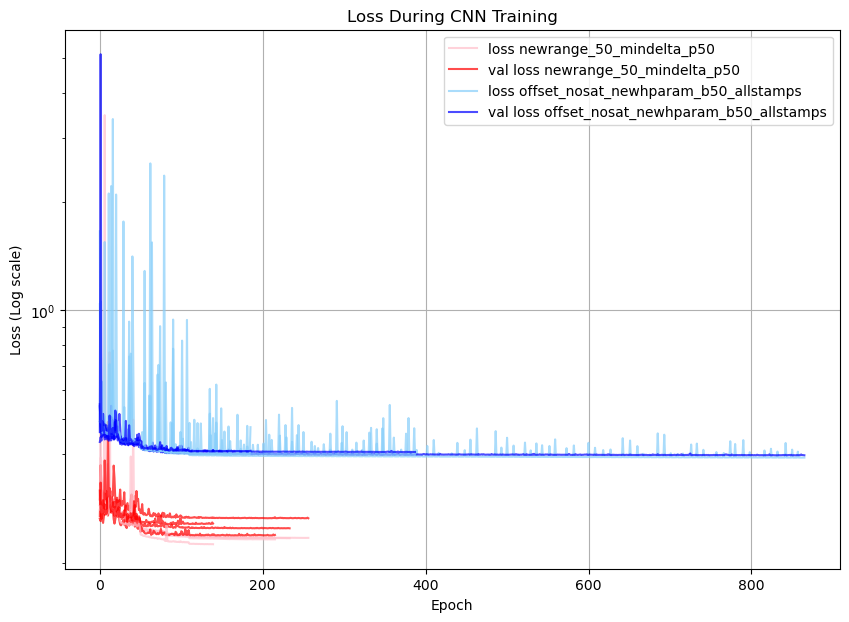

In [151]:
#'newhparam_midstreak',
#,  "newrange_25", "newrange_10",
keys = ["newrange_50_mindelta_p50","offset_nosat_newhparam_b50_allstamps"]#"newrange_25_mindelta_p50","newrange_50", "newrange_50_mindelta", ,"newrange_50_mindelta"]#, "newrange_500",  "offset_sat_small", "less_offset" #"sat_nnbigger",'offset', 
# keys = ["sat_finalhparam_div4","offset_sat_morestamps",  'sat_nnbigger', "sat_nnbigger_nopool",]
# keys = ['newhparam_midstreak',"sat_finalhparam_div4"]#,"offset_sat_morestamps"]
numbers = ["1","2","3","4"]
colors = ["red", "blue",  "purple", "green","orange"]*2
colors2 = ["pink", "lightskyblue", "mediumpurple",  "limegreen", "bisque"]*2
for i, key in enumerate(keys):
    numbers = ["1","2","3","4"]
    for number in numbers:
        loss = np.load("/home/3155/saved_loss/"+key+"_loss_history"+number+".npy")
        val_loss = np.load("/home/3155/saved_loss/"+key+"_val_loss_history"+number+".npy")
        # accuracy = np.load("/home/3155/saved_loss/"+key+"_accuracy_history"+number+".npy")
        # val_accuracy = np.load("/home/3155/saved_loss/"+key+"_val_accuracy_history"+number+".npy")
        # print(number)
        if number=="1":
            plt.plot(loss, label='loss '+key, alpha=.7, c=colors2[i])
            plt.plot(val_loss, label='val loss '+key, alpha=.7, c=colors[i])
        else:
            plt.plot(loss, alpha=.7, c=colors2[i])
            plt.plot(val_loss,  alpha=.7, c=colors[i])            
# for j, key in enumerate(['newrange']):
#     loss = np.load("/home/3155/saved_loss/"+key+"_loss_history.npy")
#     val_loss = np.load("/home/3155/saved_loss/"+key+"_val_loss_history.npy")
#     accuracy = np.load("/home/3155/saved_loss/"+key+"_accuracy_history.npy")
#     val_accuracy = np.load("/home/3155/saved_loss/"+key+"_val_accuracy_history.npy")
#     plt.plot(loss, label='loss '+key, alpha=.7, c=colors[i + j+1])
#     plt.plot(val_loss, label='val loss '+key, alpha=.7, c=colors2[i + j + 1])
plt.yscale("log")
plt.legend()
plt.xlabel("Epoch")
plt.ylabel("Loss (Log scale)")
plt.title("Loss During CNN Training")
# plt.xlim(0,45)
plt.grid()
# plt.xlim(50,90)
# plt.ylim(2e-1, 4.5e-1)
# plt.ylim(3.5e-1, 4.7e-1)
# plt.yscale("log")

In [82]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

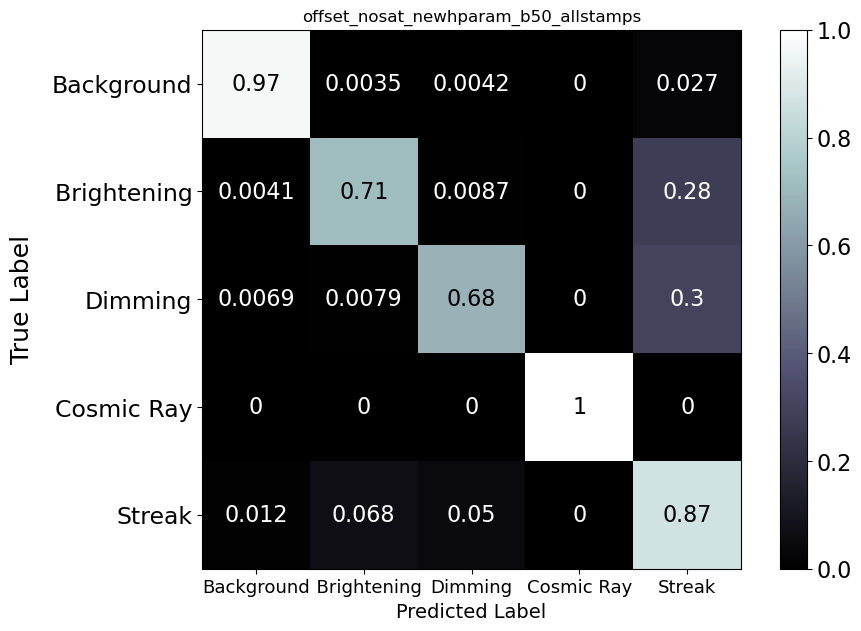

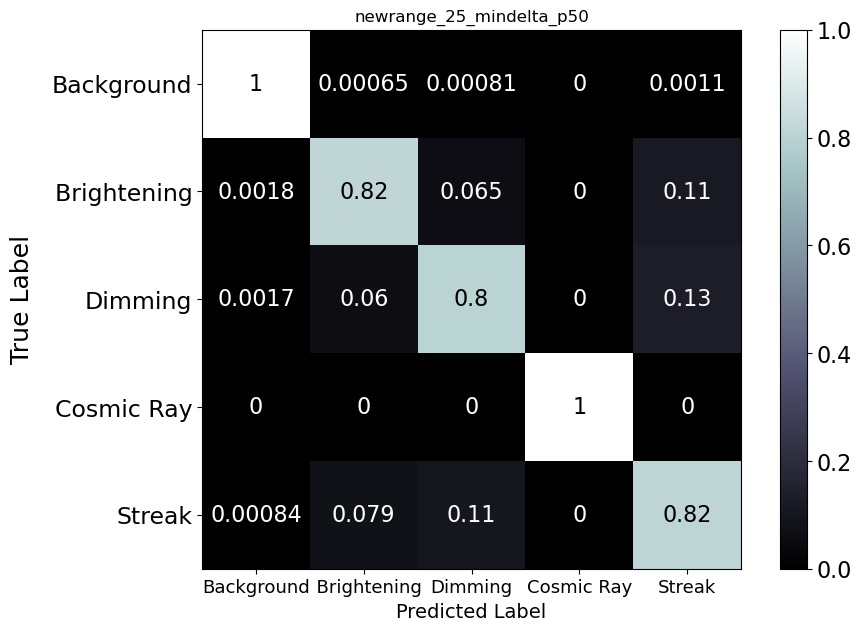

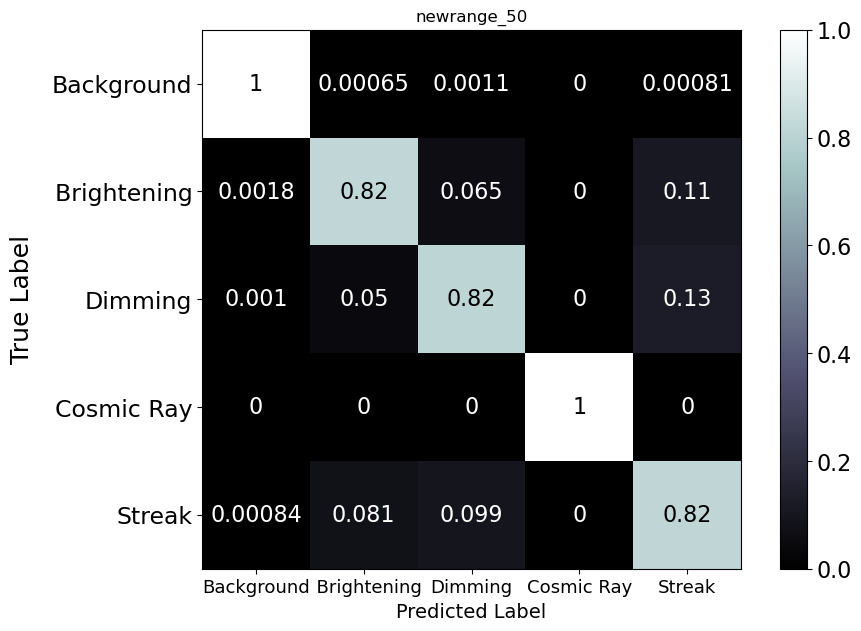

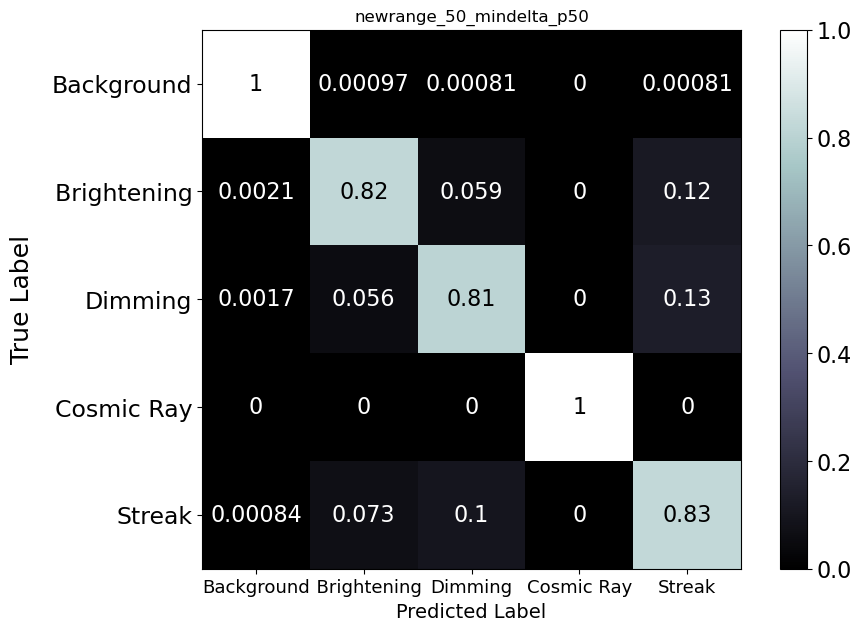

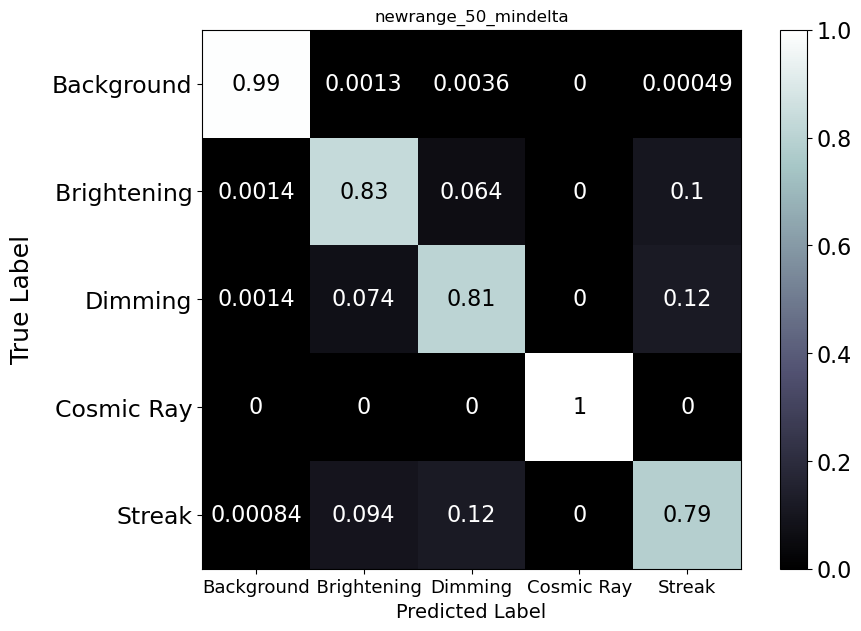

In [152]:
# keys = ['newrange_50_mindelta','newrange_25', 'newrange_50', "newrange_10"]
keys = ["offset_nosat_newhparam_b50_allstamps","newrange_25_mindelta_p50","newrange_50", "newrange_50_mindelta_p50","newrange_50_mindelta", ]
for save_name in keys:
    rff.show_confusion_matrix(save_name, sats=False)

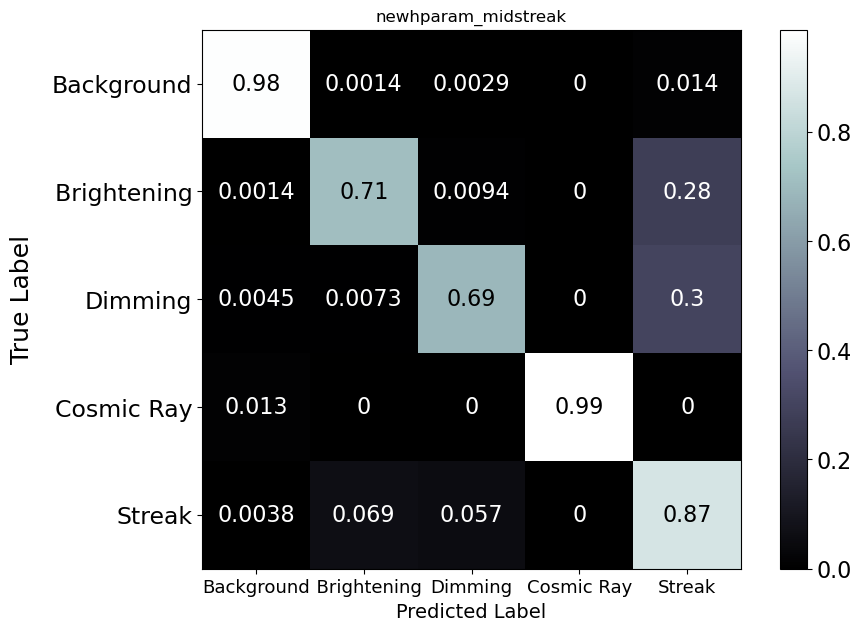

In [118]:

keys = ['newhparam_midstreak',]
for save_name in keys:
    rff.show_confusion_matrix(save_name, sats=False)

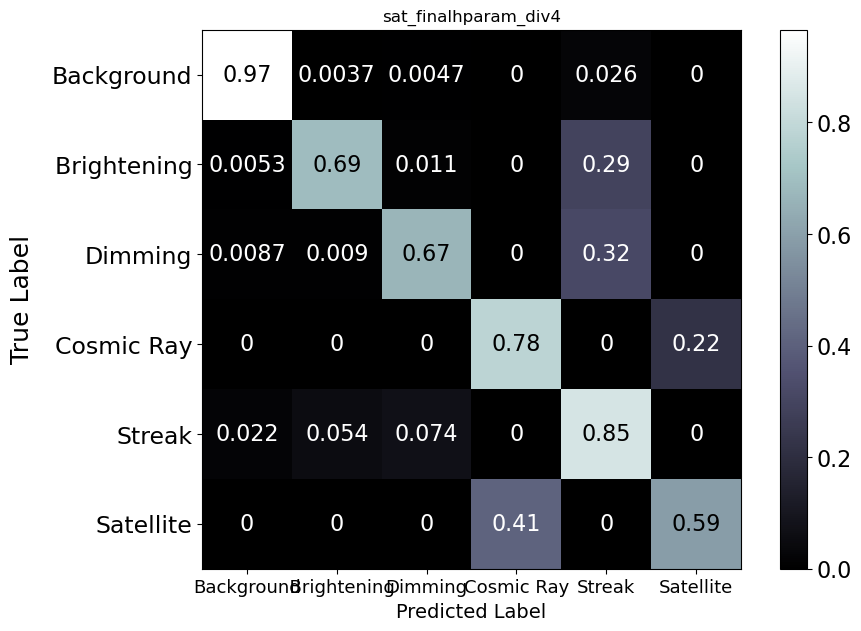

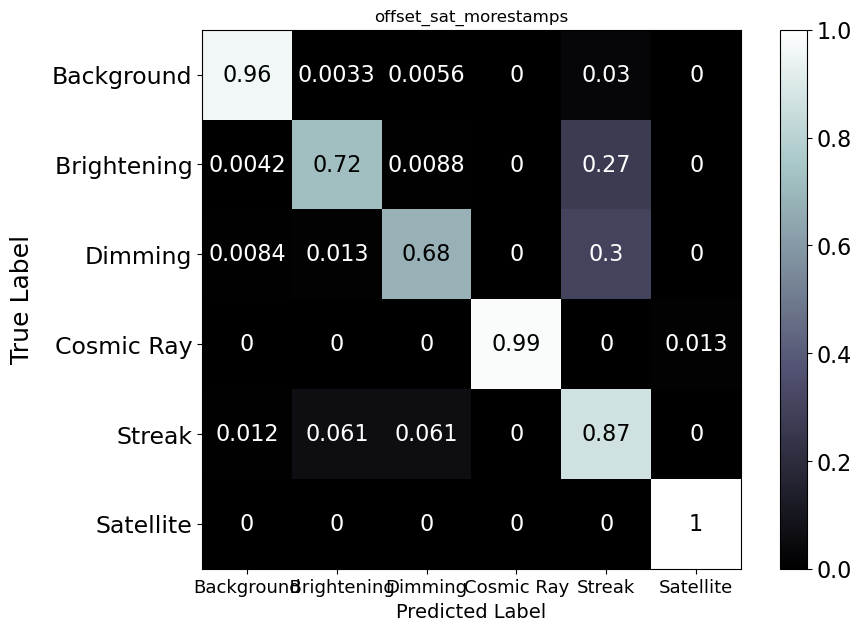

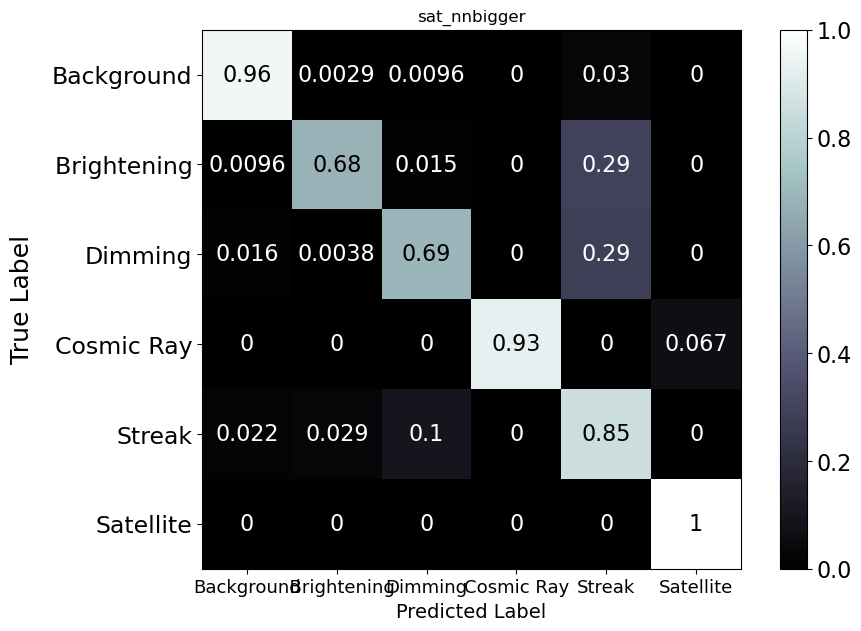

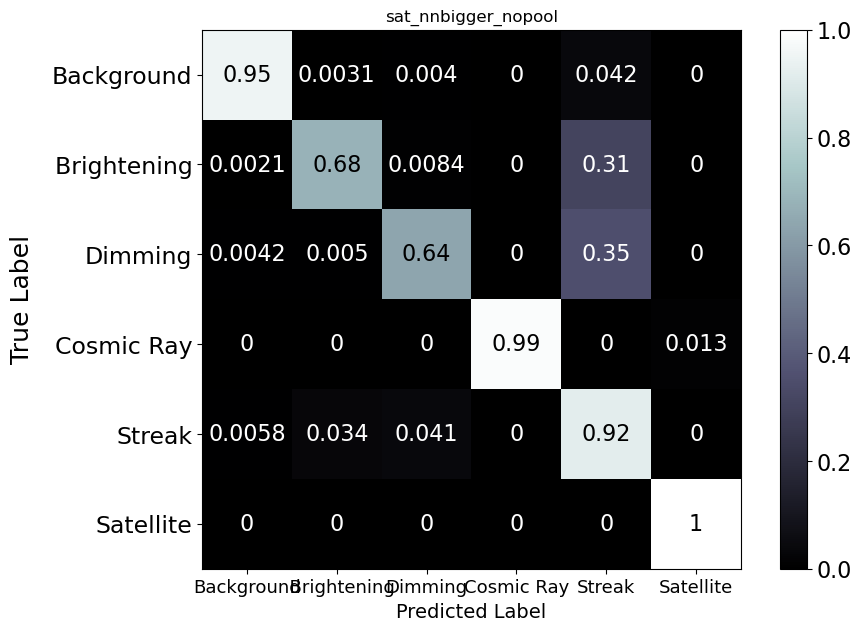

In [48]:
keys = ['sat_finalhparam_div4','offset_sat_morestamps', 'sat_nnbigger', "sat_nnbigger_nopool"]
for save_name in keys:
    rff.show_confusion_matrix(save_name, sats=True)

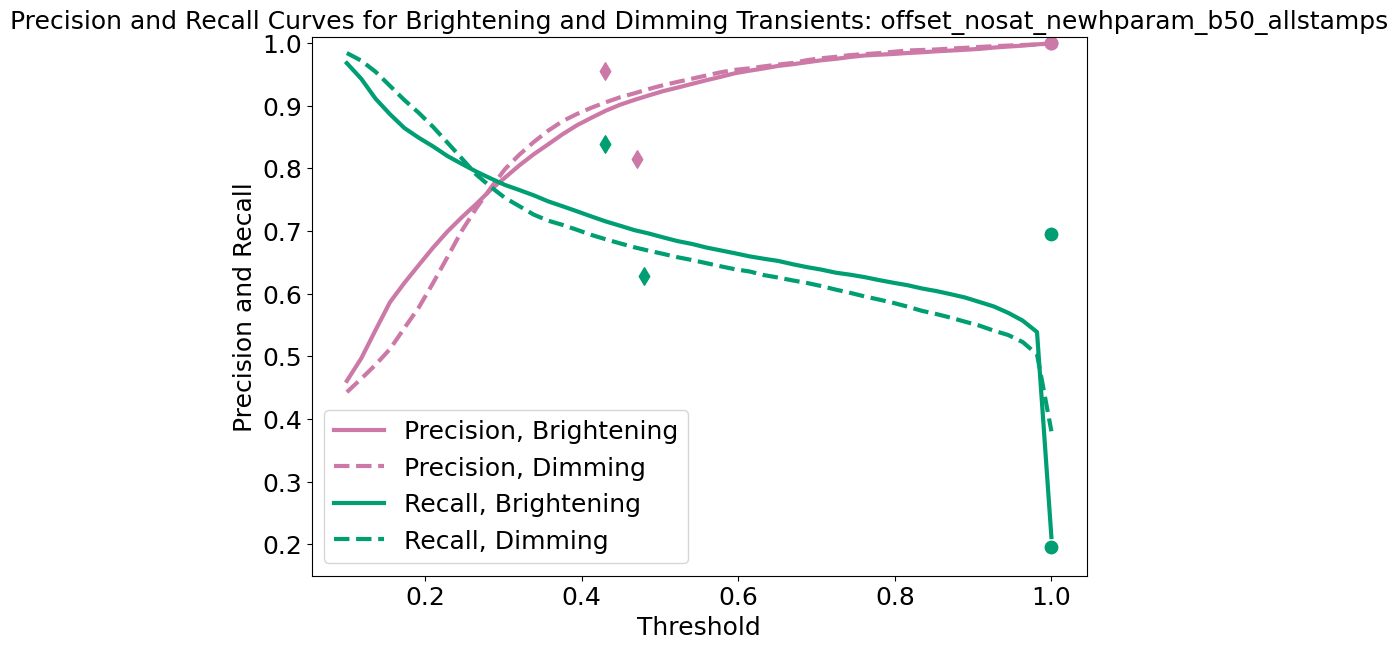

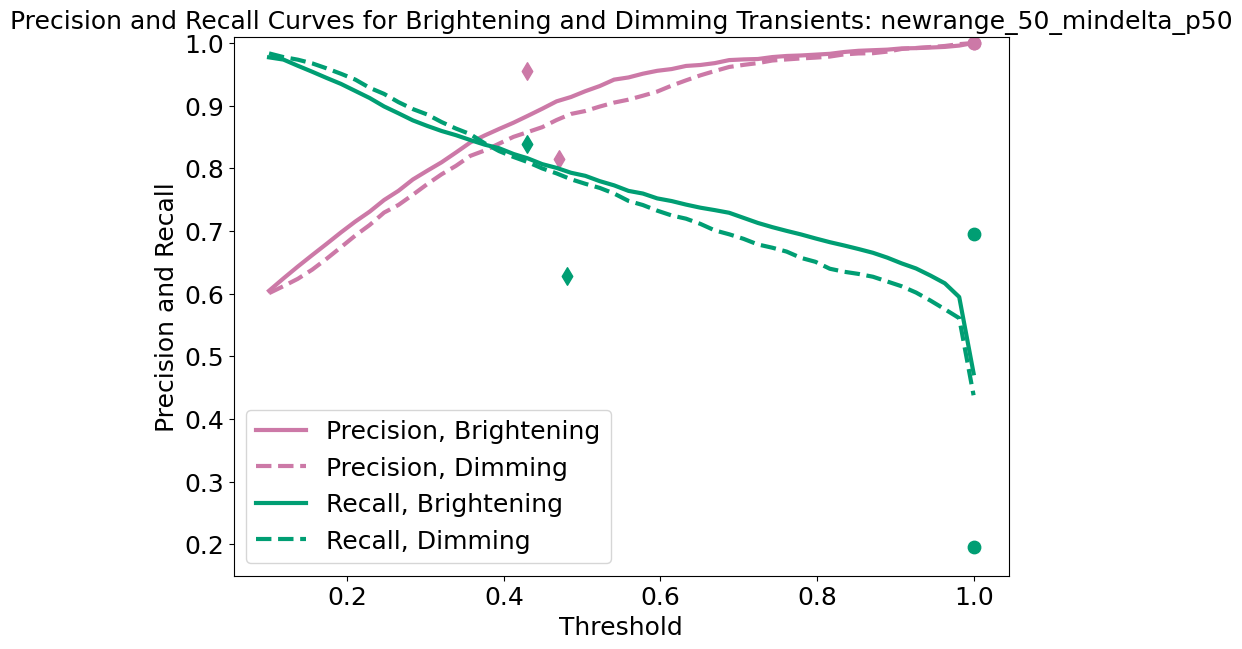

In [179]:
keys = ["offset_nosat_newhparam_b50_allstamps","newrange_50_mindelta_p50"]#, "newrange_500", "newrange_25", "newrange_50"]
for key in keys:
    plot_precision_recall(key, overlap=False)

In [180]:
np.linspace(0.1, 0.9999, 50)

array([0.1       , 0.11836531, 0.13673061, 0.15509592, 0.17346122,
       0.19182653, 0.21019184, 0.22855714, 0.24692245, 0.26528776,
       0.28365306, 0.30201837, 0.32038367, 0.33874898, 0.35711429,
       0.37547959, 0.3938449 , 0.4122102 , 0.43057551, 0.44894082,
       0.46730612, 0.48567143, 0.50403673, 0.52240204, 0.54076735,
       0.55913265, 0.57749796, 0.59586327, 0.61422857, 0.63259388,
       0.65095918, 0.66932449, 0.6876898 , 0.7060551 , 0.72442041,
       0.74278571, 0.76115102, 0.77951633, 0.79788163, 0.81624694,
       0.83461224, 0.85297755, 0.87134286, 0.88970816, 0.90807347,
       0.92643878, 0.94480408, 0.96316939, 0.98153469, 0.9999    ])

In [154]:
def plot_precision_recall(save_name, overlap=False):
    label_pred_te = np.load("/home/3155/saved_loss/label_pred_te_"+save_name+".npy")
    targ_te = np.load("/home/3155/saved_loss/targ_te_"+save_name+".npy")
    threshes = np.linspace(0.1, 0.9999, 50)
    prec_br = []
    prec_dim = []
    rec_br = []
    rec_dim = []
    for thr in threshes:
        tp_thr = np.sum(targ_te[label_pred_te[:, 1] > thr] == 1)
        fp_thr = np.sum(targ_te[label_pred_te[:, 1] > thr] != 1)
        fn_thr = np.sum(targ_te[label_pred_te[:, 1] < thr] == 1)
        precision_thr = tp_thr / (tp_thr + fp_thr)
        recall_thr = tp_thr / (tp_thr + fn_thr)
        prec_br.append(precision_thr)
        rec_br.append(recall_thr)
        tp_thr = np.sum(targ_te[label_pred_te[:, 2] > thr] == 2)
        fp_thr = np.sum(targ_te[label_pred_te[:, 2] > thr] != 2)
        fn_thr = np.sum(targ_te[label_pred_te[:, 2] < thr] == 2)
        precision_thr = tp_thr / (tp_thr + fp_thr)
        recall_thr = tp_thr / (tp_thr + fn_thr)
        prec_dim.append(precision_thr)
        rec_dim.append(recall_thr)
    plt.plot(threshes, prec_br, label="Precision, Brightening", linewidth=3, c="#cc79a7")
    plt.plot(
        threshes,
        prec_dim,
        label="Precision, Dimming",
        linewidth=3,
        linestyle="dashed",
        c="#cc79a7",
    )
    plt.plot(threshes, rec_br, label="Recall, Brightening", linewidth=3, c="#009e73")
    plt.plot(
        threshes,
        rec_dim,
        label="Recall, Dimming",
        linewidth=3,
        linestyle="dashed",
        c="#009e73",
    )
    # plt.plot(threshes, np.full( len(threshes), 0.9550351288056206), label="Precision Brightening Max")
    # plt.plot(threshes, np.full( len(threshes), 0.8384046052631579), label="Recall Brightening Max")
    # plt.plot(threshes, np.full( len(threshes), 0.8152115693626139), label="Precision Dimming Max")
    # plt.plot(threshes, np.full( len(threshes), 0.6284062758051198), label="Recall Dimming Max")
    plt.scatter(0.43, 0.9550351288056206, s=80, marker="d", c="#cc79a7")
    plt.scatter(0.47, 0.8152115693626139, s=80, marker="d", c="#cc79a7")
    plt.scatter(0.43, 0.8384046052631579, s=80, marker="d", c="#009e73")

    plt.scatter(0.48, 0.6284062758051198, s=80, marker="d", c="#009e73")

    plt.scatter(0.9999, 1, s=80, marker="o", c="#cc79a7")
    plt.scatter(0.9999, 1, s=80, marker="o", c="#cc79a7")
    plt.scatter(0.9999, 0.695, s=80, marker="o", c="#009e73")
    plt.scatter(0.9999, 0.196, s=80, marker="o", c="#009e73")

    plt.legend(fontsize=18)
    plt.title(
        "Precision and Recall Curves for Brightening and Dimming Transients: "+save_name, fontsize=18
    )
    plt.xlabel("Threshold", fontsize=18)
    plt.ylabel("Precision and Recall", fontsize=18)
    plt.ylim(0.15, 1.01)
    plt.tick_params(axis="both", labelsize=18)
    if overlap==False:
        plt.show()

offset_nosat_newhparam_b50_allstamps


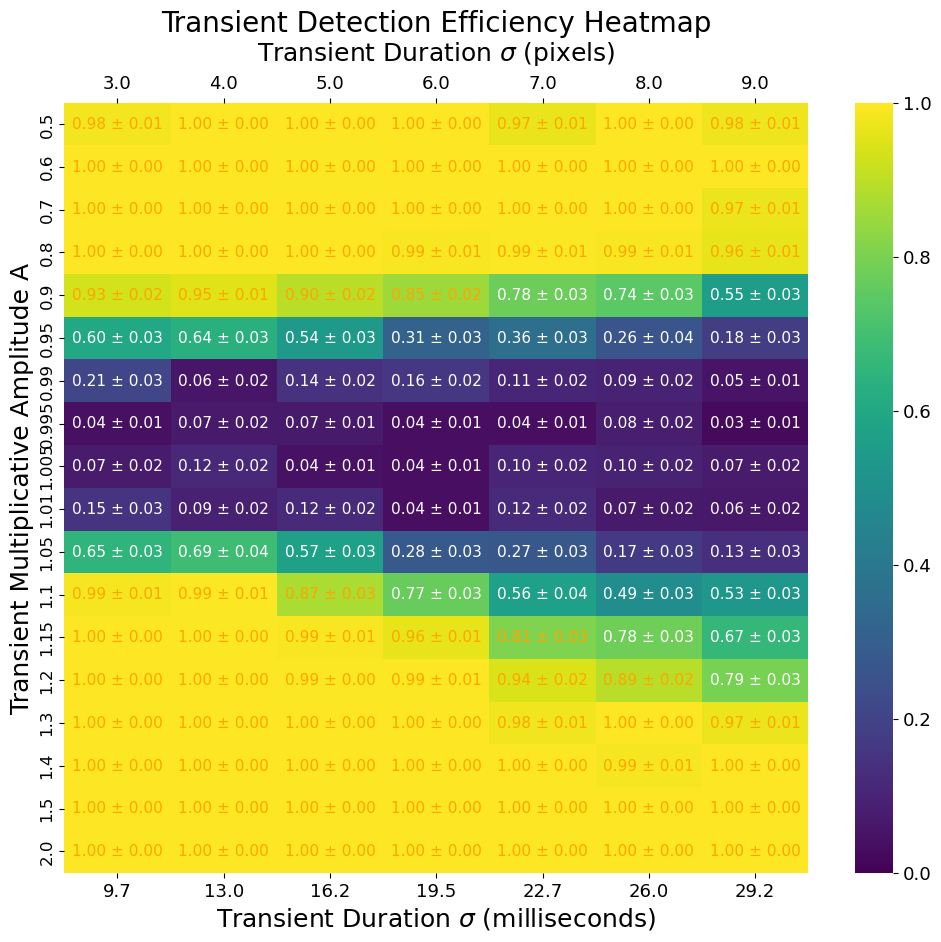

In [3]:
for save_name in ['offset_nosat_newhparam_b50_allstamps']:
    print(save_name)
    rff.heatmap(save_name)
    # im = Image.open("/home/3155/saved_loss/heatmap_"+save_name+".png")
    # im.show()

In [157]:
from tensorflow import keras

2026-03-19 11:39:27.169856: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [158]:
#let's test on other unseen set
# - we don't know whether this is contaminated in our training set
save_name = "offset_nosat_newhparam_b50_allstamps"
model = keras.models.load_model("/home/3155/CNN_"+save_name)




2026-03-19 11:40:54.037002: I tensorflow/core/common_runtime/process_util.cc:146] Creating new thread pool with default inter op setting: 2. Tune using inter_op_parallelism_threads for best performance.


In [161]:
feat_te = np.load("/home/3155/saved_loss/newrange_25_mindelta_p50_feat_te.npy")
# label_pred_te = model.predict(feat_te)
#jk we didn't save iit

FileNotFoundError: [Errno 2] No such file or directory: '/home/3155/saved_loss/newrange_25_mindelta_p50_feat_te.npy'

In [162]:
info = np.load("/home/3155/saved_loss/offset_nosat_newhparam_b50_allstamps_info_te.npy")

In [176]:
np.sum(info[:,-1]>13)

7534

In [175]:
info[(info[:,-1]==0) | (info[:,-1]>10)]

array([[7.750e+02, 0.000e+00, 0.000e+00, 2.045e+03, 2.624e+03, 0.000e+00],
       [7.350e+02, 5.000e-01, 8.000e+00, 1.956e+03, 2.982e+03, 1.300e+01],
       [4.810e+02, 1.050e+00, 6.000e+00, 2.216e+03, 2.938e+03, 0.000e+00],
       ...,
       [4.300e+02, 7.000e-01, 4.000e+00, 3.230e+02, 2.747e+03, 1.600e+01],
       [4.740e+02, 1.400e+00, 4.000e+00, 3.870e+02, 4.290e+02, 0.000e+00],
       [1.099e+03, 0.000e+00, 0.000e+00, 8.400e+02, 1.340e+03, 0.000e+00]])

Text(0.5, 0, 'distance')

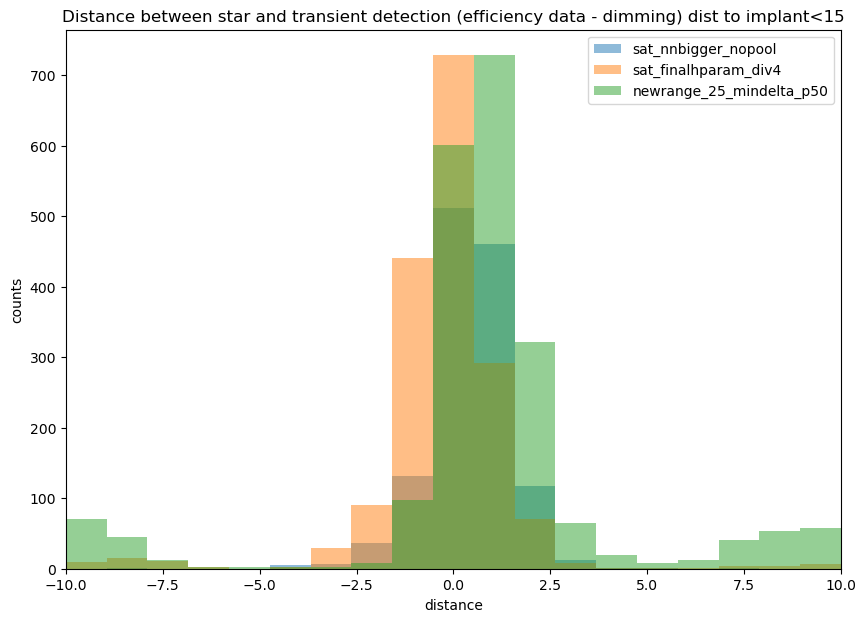

In [66]:
for key in df_names[-3:]:
    test = dfs_neg[key][np.abs(dfs_neg[key]['dist_to_implant'])<15]
    plt.hist((test['closest_x']-(test['col_from_nn']+10)), 
             bins = np.linspace(-10,10,20),
            alpha=.5, label=key)
plt.xlim(-10,10)
plt.legend()
plt.title("Distance between star and transient detection (efficiency data - dimming) dist to implant<15")
plt.ylabel("counts")
plt.xlabel("distance")

Text(0.5, 0, 'distance')

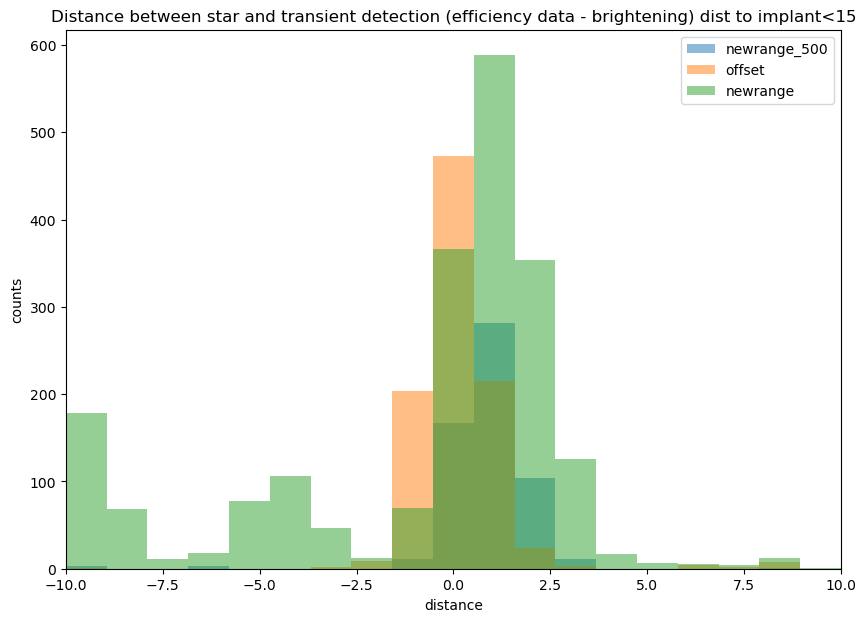

In [19]:
for key in df_names:
    test = dfs_pos[key][np.abs(dfs_pos[key]['dist_to_implant'])<15]
    plt.hist((test['closest_x']-(test['col_from_nn']+10)), 
             bins = np.linspace(-10,10,20),
            alpha=.5, label=key)
plt.xlim(-10,10)
plt.legend()
plt.title("Distance between star and transient detection (efficiency data - brightening) dist to implant<15")
plt.ylabel("counts")
plt.xlabel("distance")

Text(0.5, 0, 'distance')

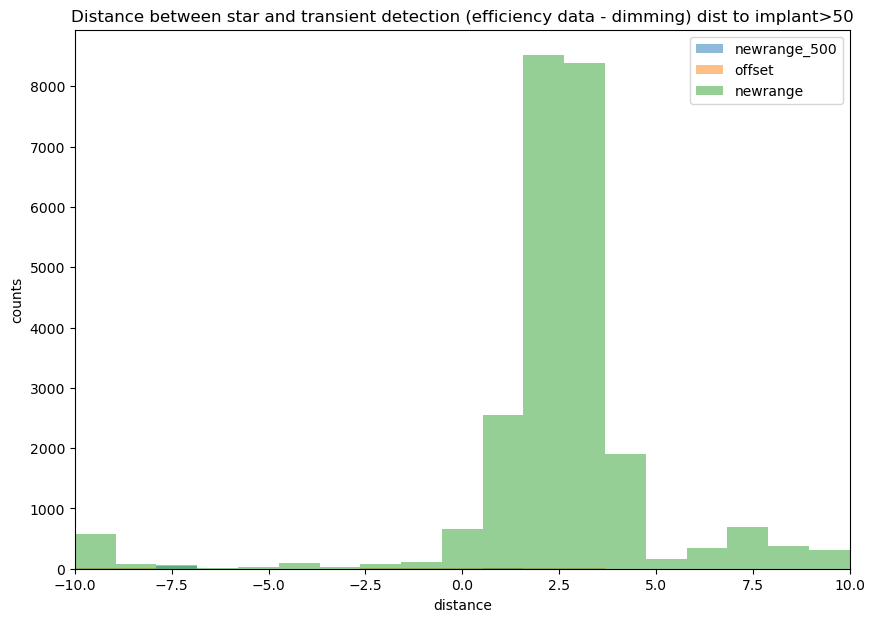

In [20]:
for key in df_names:
    test = dfs_neg[key][np.abs(dfs_neg[key]['dist_to_implant'])>50]
    plt.hist((test['closest_x']-(test['col_from_nn']+10)), 
             bins = np.linspace(-10,10,20),
            alpha=.5, label=key)
plt.xlim(-10,10)
plt.legend()
plt.title("Distance between star and transient detection (efficiency data - dimming) dist to implant>50")
plt.ylabel("counts")
plt.xlabel("distance")

Text(0.5, 0, 'distance')

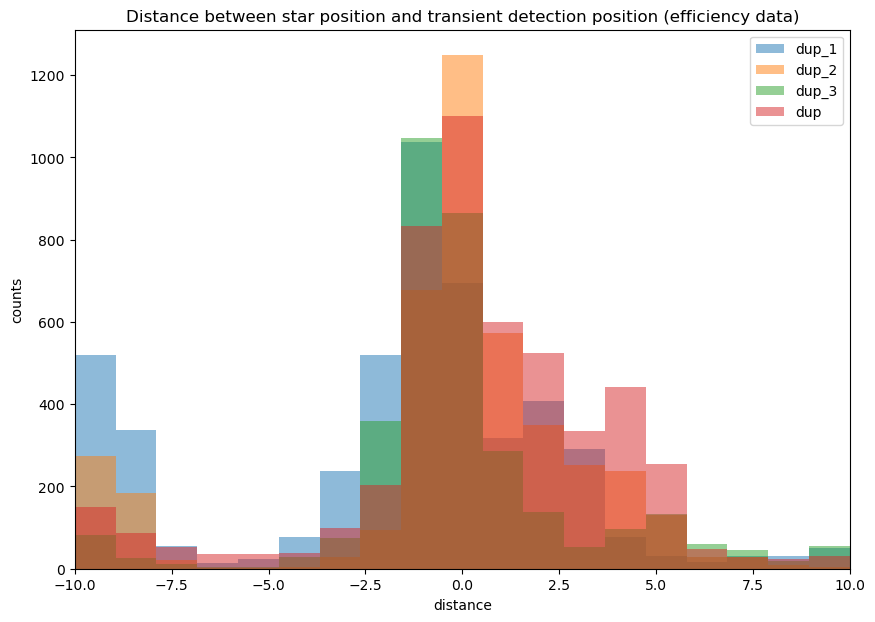

In [39]:
for key in df_names_2[:4]:
    test = dfs_neg[key][np.abs(dfs_neg[key]['dist_to_implant'])<40]
    plt.hist((test['closest_x']-(test['col_from_nn']+10)), 
             bins = np.linspace(-10,10,20),
            alpha=.5, label=key)
plt.xlim(-10,10)
plt.legend()
plt.title("Distance between star position and transient detection position (efficiency data)")
plt.ylabel("counts")
plt.xlabel("distance")

Text(0.5, 0, 'distance')

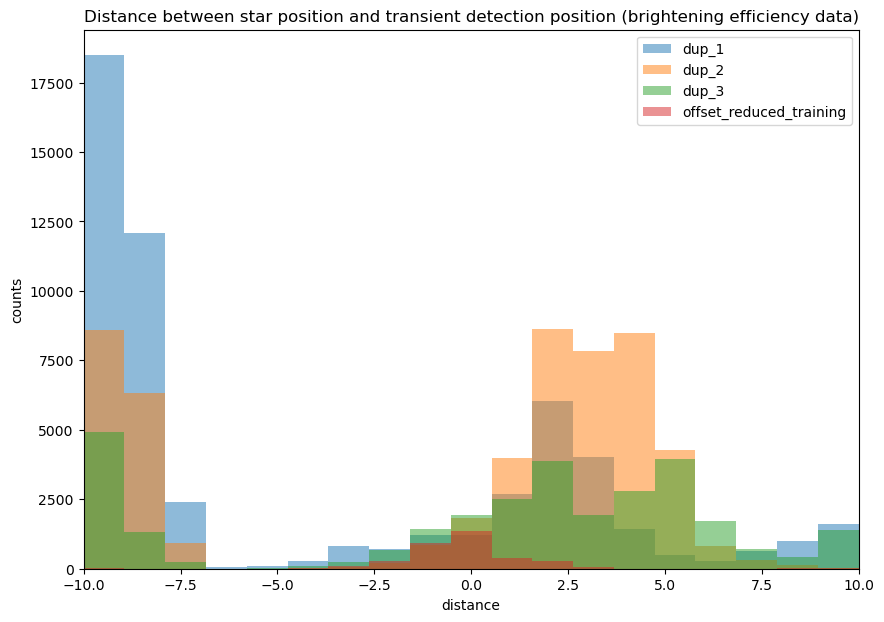

In [197]:
for key in df_names_1:
    plt.hist((dfs_neg[key]['closest_x']-(dfs_neg[key]['col_from_nn']+10)), 
             bins = np.linspace(-10,10,20),
            alpha=.5, label=key)
plt.xlim(-10,10)
plt.legend()
plt.title("Distance between star position and transient detection position (brightening efficiency data)")
plt.ylabel("counts")
plt.xlabel("distance")

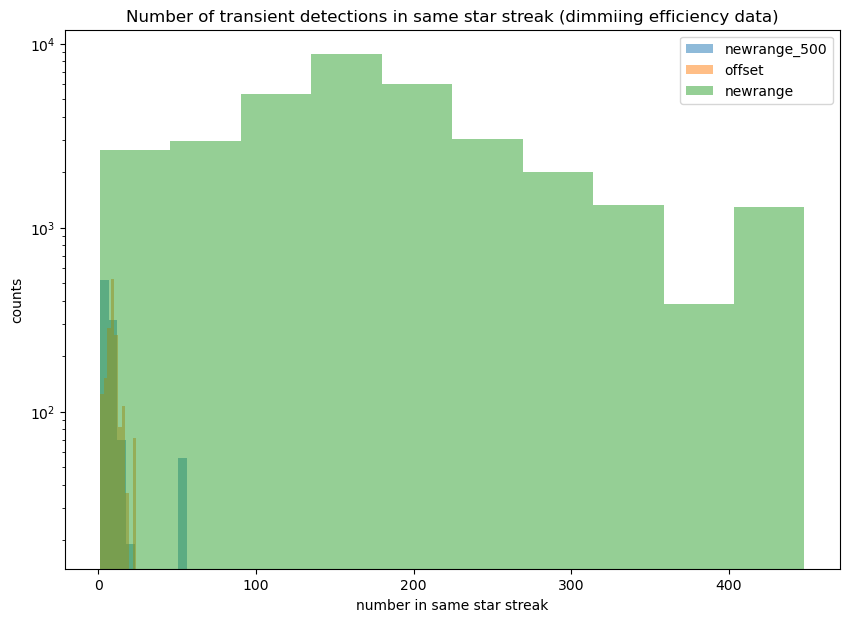

In [21]:
for key in df_names:
    plt.hist(dfs_neg[key]['num_in_file_in_star'], 
             # bins = np.linspace(-10,10,20),
            alpha=.5, label=key)
# plt.xlim(-10,10)
plt.legend()
plt.title("Number of transient detections in same star streak (dimmiing efficiency data)")
plt.ylabel("counts")
plt.xlabel("number in same star streak")
plt.yscale("log")

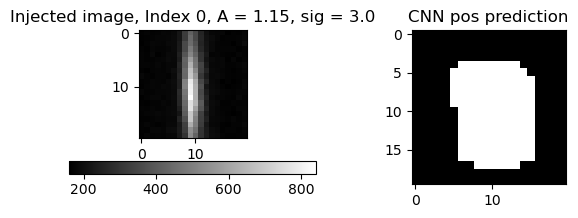

In [211]:
rff.inspect_stamp_and_map(dforiginal2, 0)

In [68]:
dfs_pos.keys()

dict_keys(['newrange_10', 'newrange_25', 'offset_sat_morestamps', 'newrange_50', 'newrange_500', 'offset', 'newrange', 'less_offset', 'newrange_50_mindelta_p50', 'sat_nnbigger_nopool', 'sat_finalhparam_div4', 'newrange_25_mindelta_p50'])

In [119]:
#okay so let's look at some examples where we're 10 pixels away
dfs_pos["sat_nnbigger_nopool"][dfs_pos["sat_nnbigger_nopool"]['Diff']>10]

,Unnamed: 0.1,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,closest_y,...,brightness_ranking,quadrant,num_in_file_in_star,dup_indices,is_smaller_dup,dist_to_implant,row_from_implant,col_from_implant,A_from_implant,sig_from_implant
189,189,189,ztf_20221020148032_000686_zg_c03_x_0011.,2,pos,906.263158,1665.842105,19,1689.0,1190.0,...,4,2,7.0,[],0.0,244.565543,672.0,1688.0,1.400,9.0
207,207,207,ztf_20221020148032_000686_zg_c03_x_0011.,2,pos,3026.000000,475.000000,71,561.0,2378.0,...,23,2,3.0,[208],0.0,656.958142,2449.0,190.0,1.050,6.0
208,208,208,ztf_20221020148032_000686_zg_c03_x_0011.,2,pos,3034.500000,472.000000,8,561.0,2378.0,...,23,2,3.0,[207],1.0,663.237702,2449.0,190.0,1.050,6.0
235,235,235,ztf_20221020148032_000686_zg_c03_x_0011.,2,neg,3016.375000,475.781250,32,561.0,2378.0,...,23,2,3.0,[],0.0,648.728324,2449.0,190.0,1.050,6.0
405,405,405,ztf_20221020154120_000640_zi_c11_x_0015.,2,pos,2682.795775,18.637324,284,307.0,1135.0,...,18,2,2.0,[],0.0,502.313826,2373.0,416.0,10.000,5.0
430,430,430,ztf_20221020154120_000640_zi_c11_x_0015.,2,neg,2691.342857,19.707143,140,307.0,1135.0,...,18,2,2.0,[],0.0,506.982449,2373.0,416.0,10.000,5.0
457,457,457,ztf_20221020138241_000686_zi_c02_x_0029.,3,pos,2932.954545,1304.727273,22,1433.0,2418.0,...,20,3,2.0,[458],0.0,648.004829,2403.0,1673.0,1.500,4.0
458,458,458,ztf_20221020138241_000686_zi_c02_x_0029.,3,pos,2945.181818,1304.090909,11,1433.0,2418.0,...,20,3,2.0,[457],1.0,658.574594,2403.0,1673.0,1.500,4.0
802,802,802,ztf_20221020148032_000686_zg_c16_x_0014.,4,pos,1159.432836,814.044776,67,839.0,625.0,...,16,4,2.0,[],0.0,106.668526,1197.0,721.0,1.005,9.0
840,840,840,ztf_20221020148032_000686_zg_c16_x_0014.,4,neg,1150.392857,814.964286,28,839.0,625.0,...,16,4,2.0,[],0.0,110.220940,1197.0,721.0,1.005,9.0


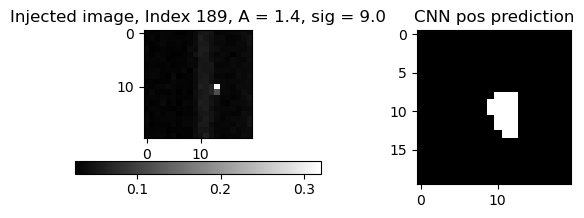

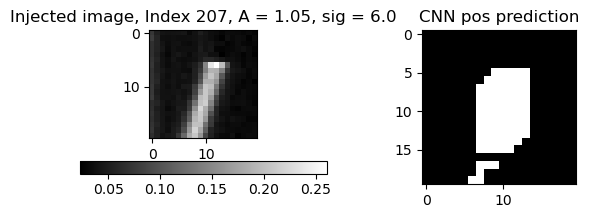

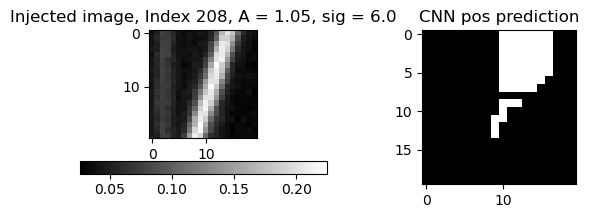

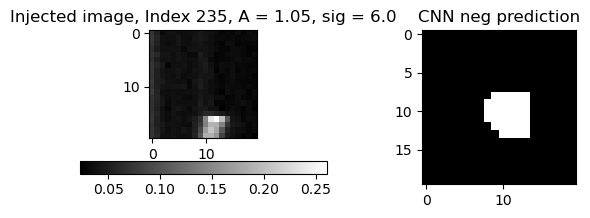

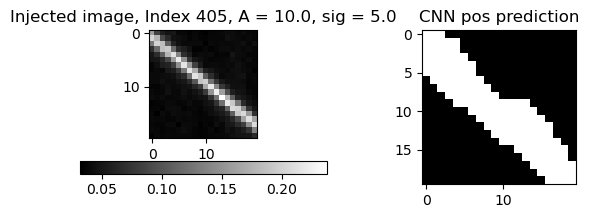

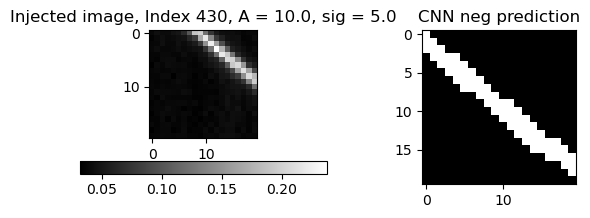

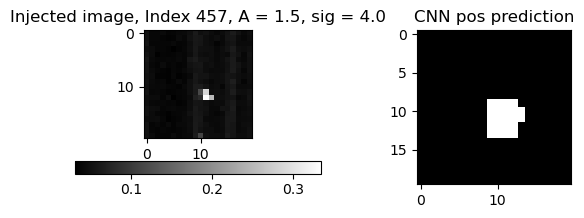

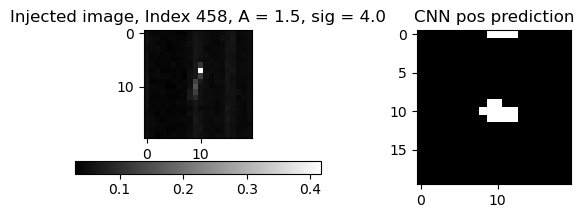

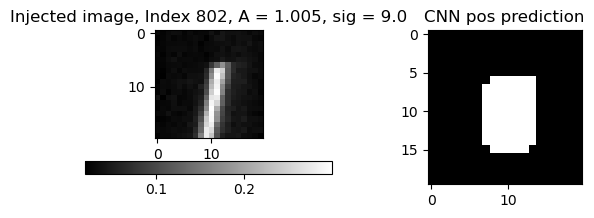

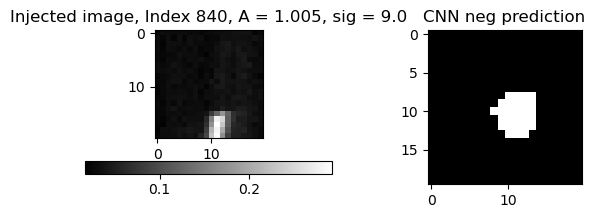

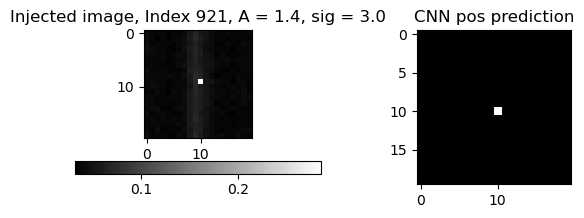

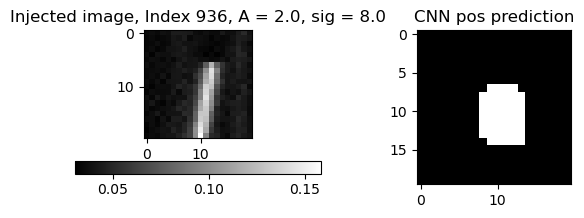

In [120]:
for index in dfs_pos["sat_nnbigger_nopool"][dfs_pos["sat_nnbigger_nopool"]['Diff']>10].index:
    rff.inspect_stamp_and_map(dfs_pos["sat_nnbigger_nopool"], index, posneg='pos', pdirec='predsarrays_sat_nnbigger_nopool')

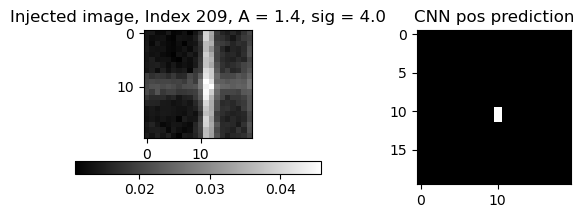

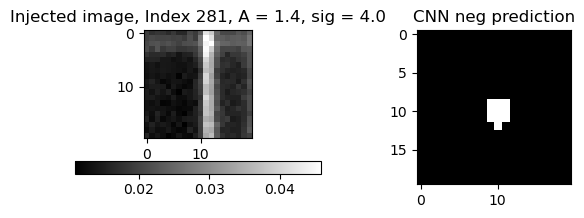

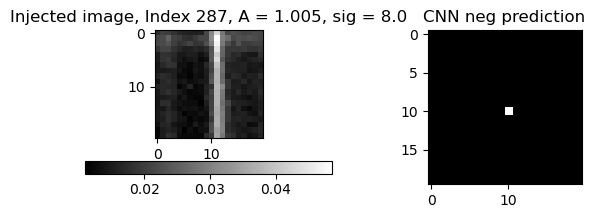

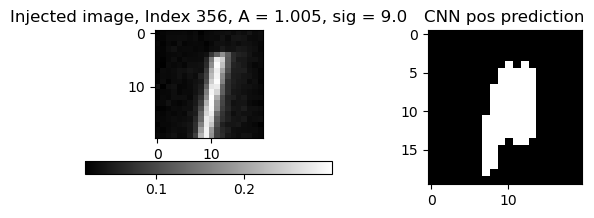

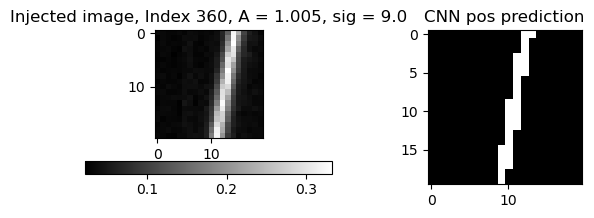

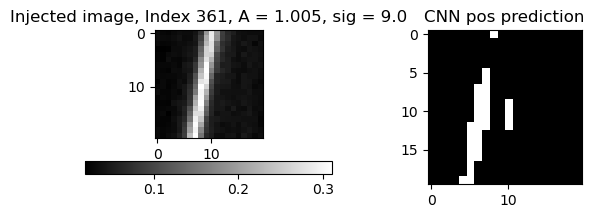

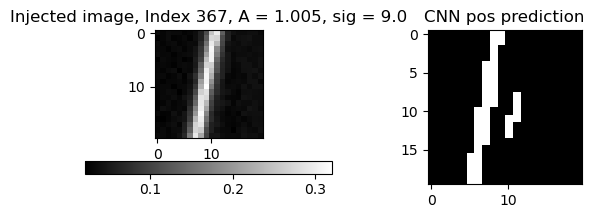

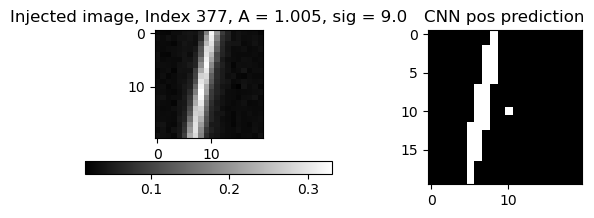

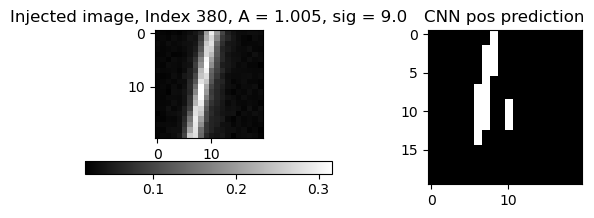

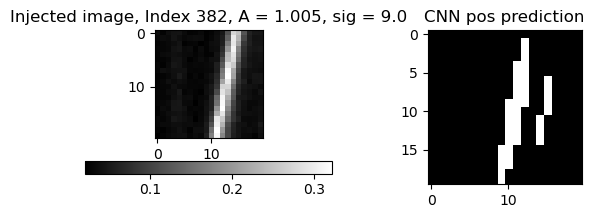

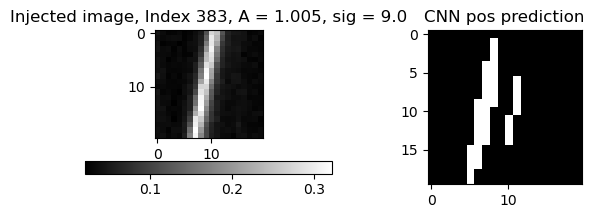

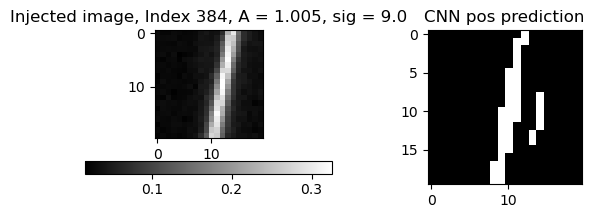

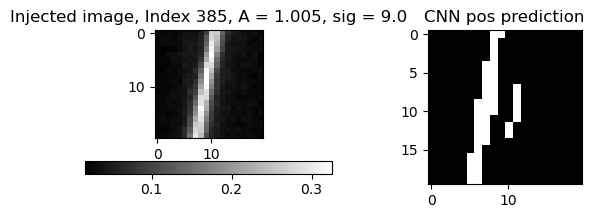

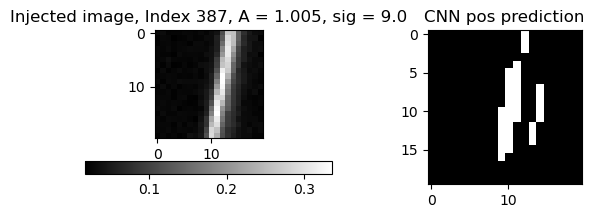

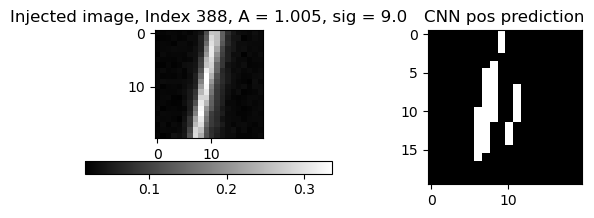

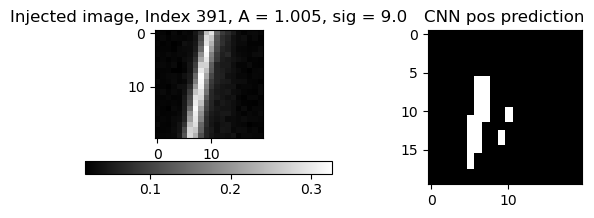

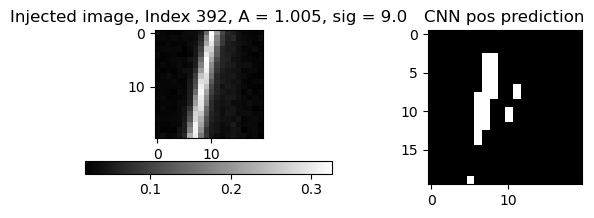

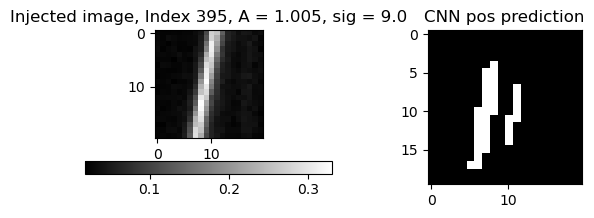

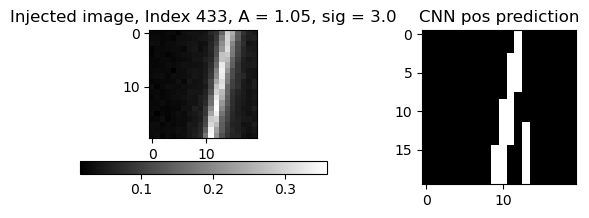

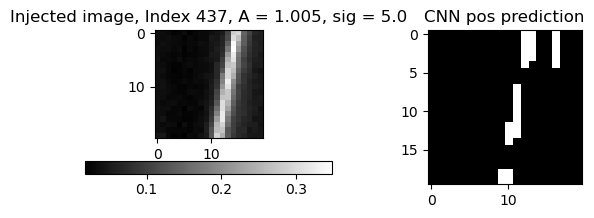

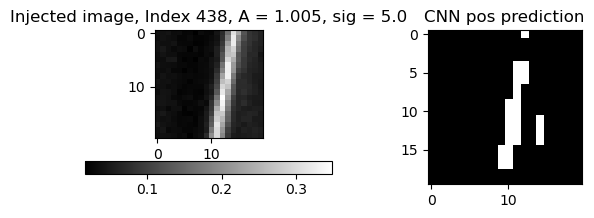

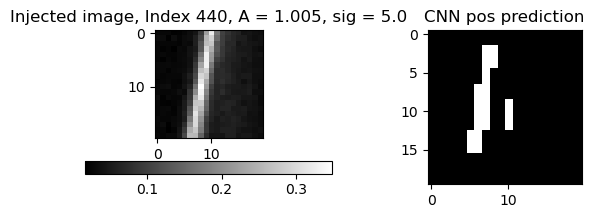

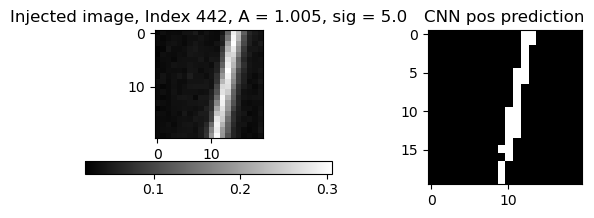

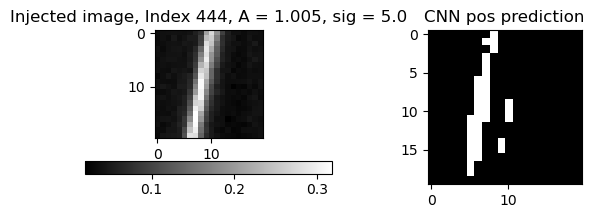

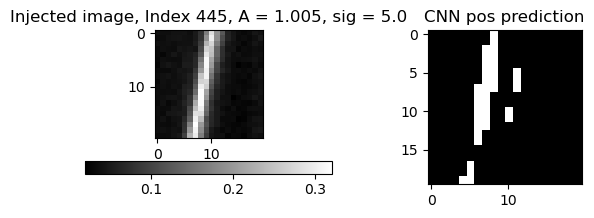

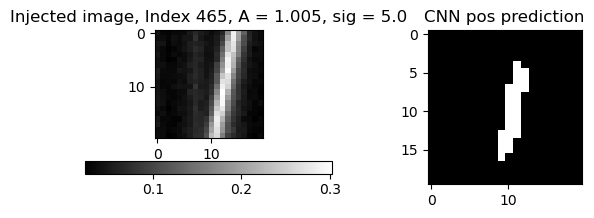

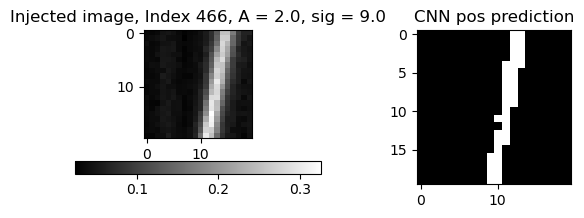

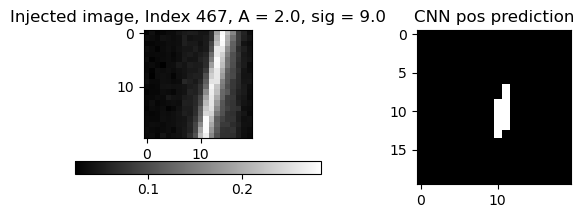

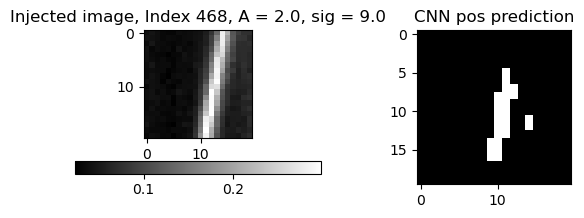

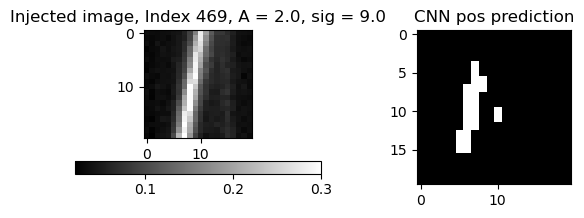

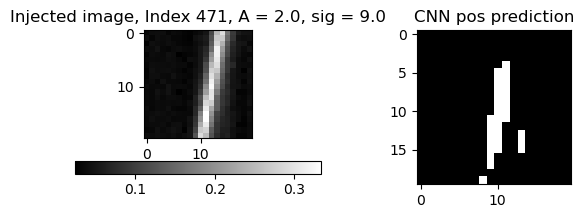

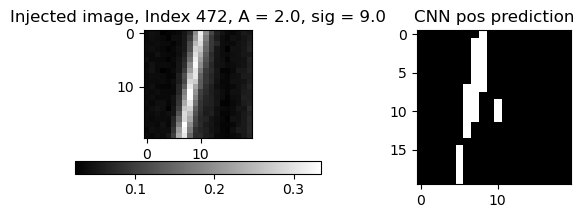

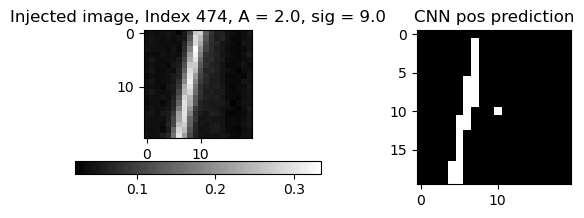

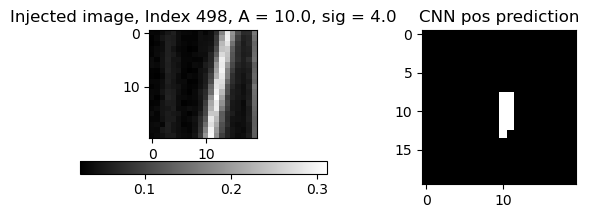

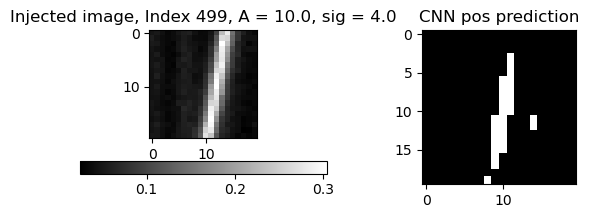

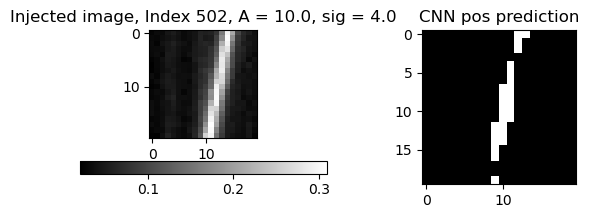

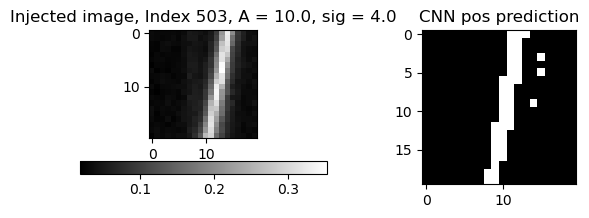

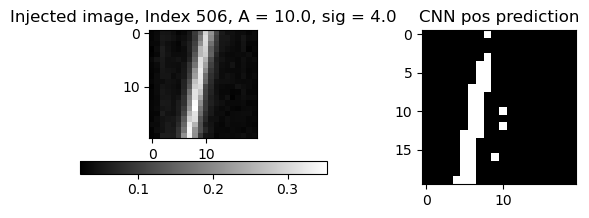

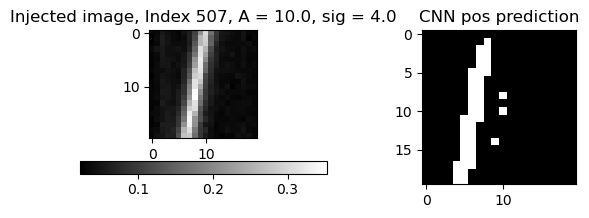

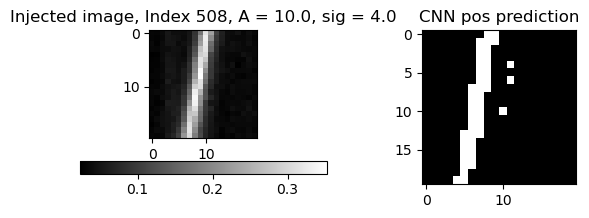

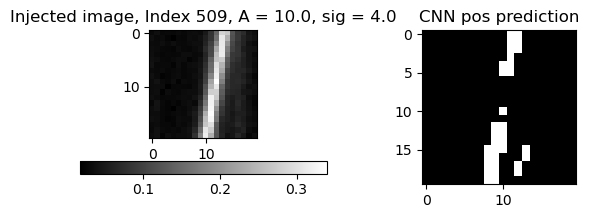

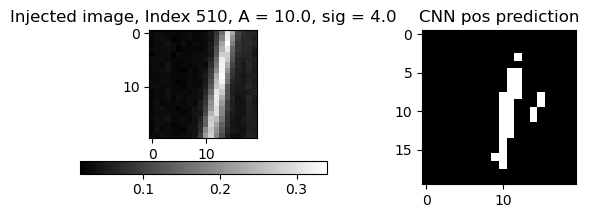

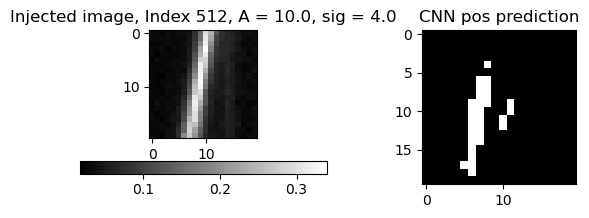

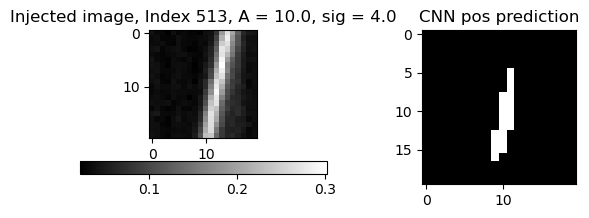

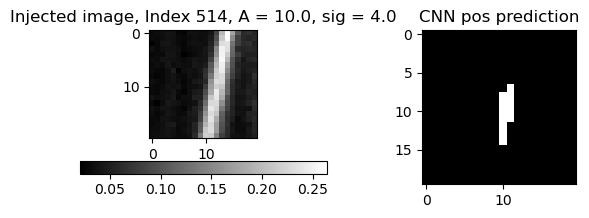

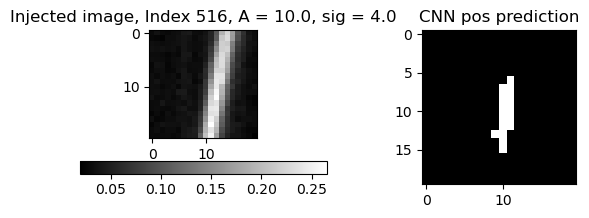

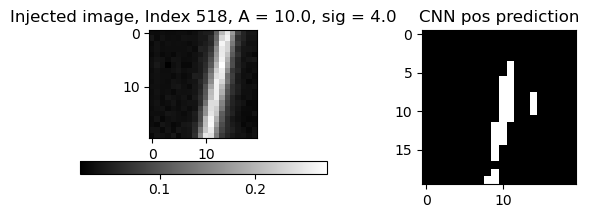

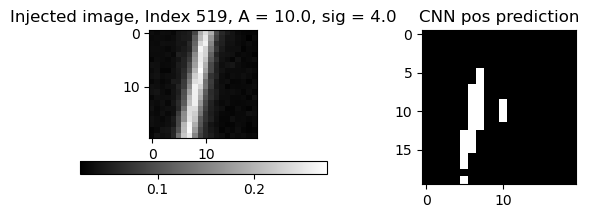

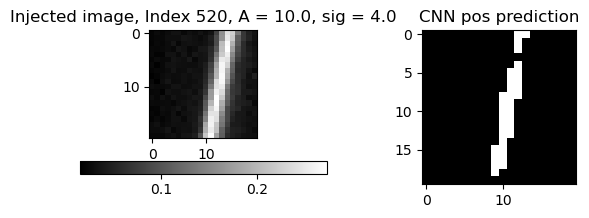

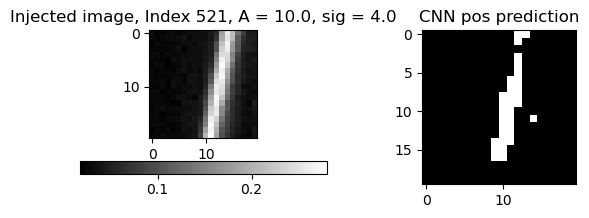

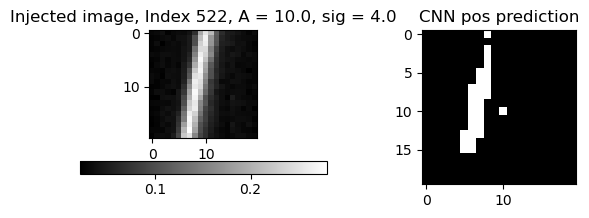

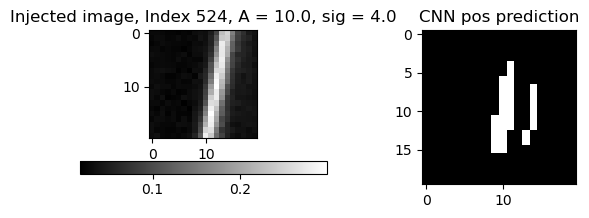

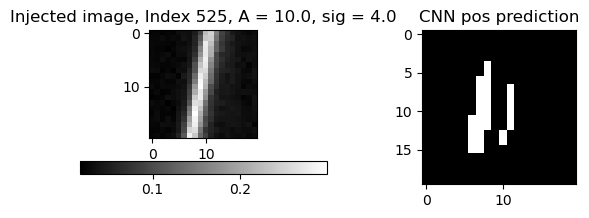

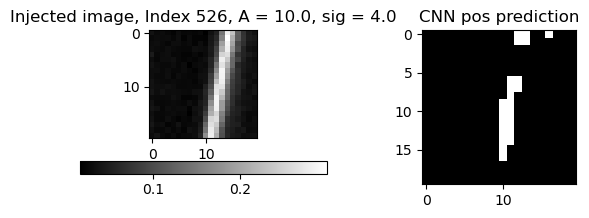

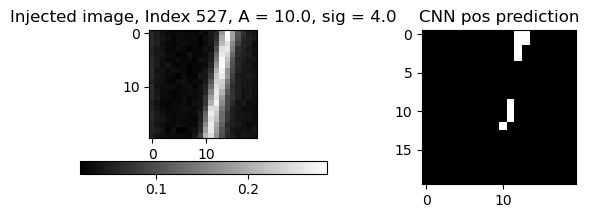

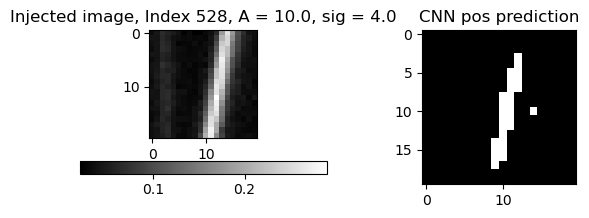

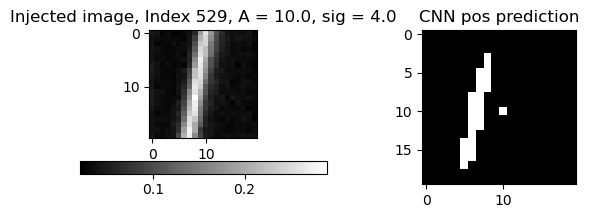

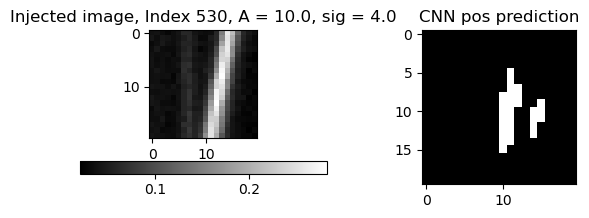

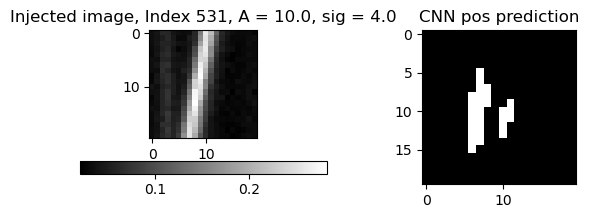

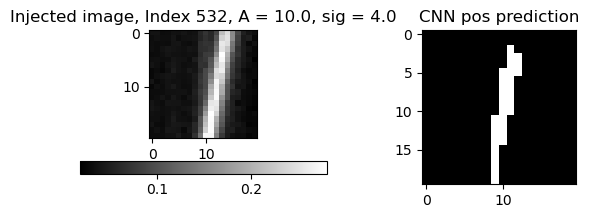

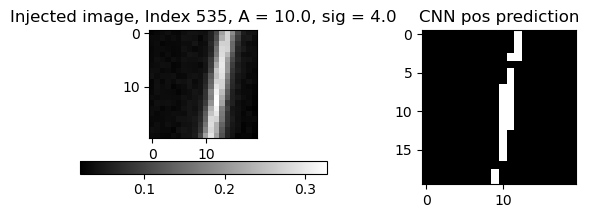

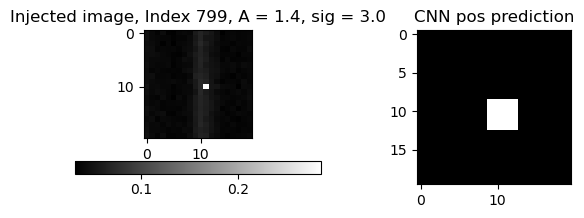

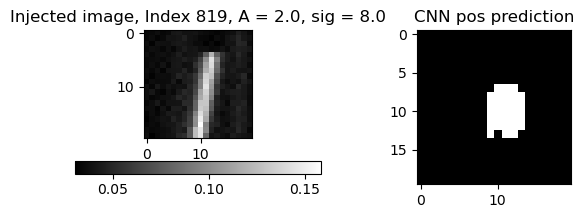

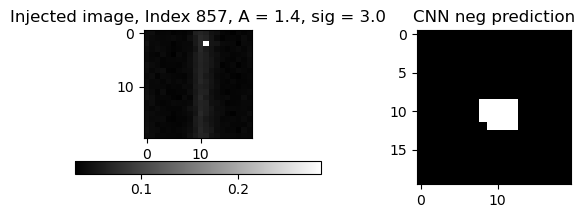

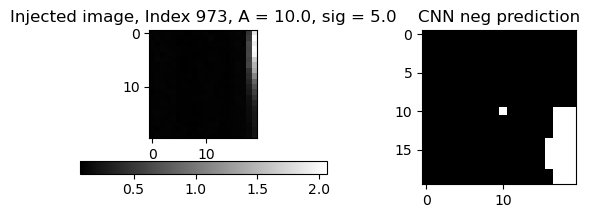

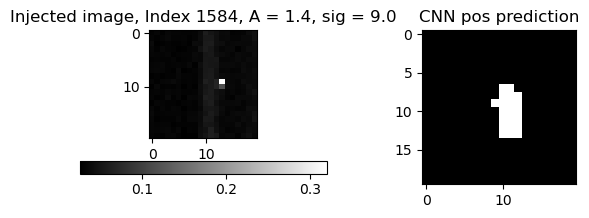

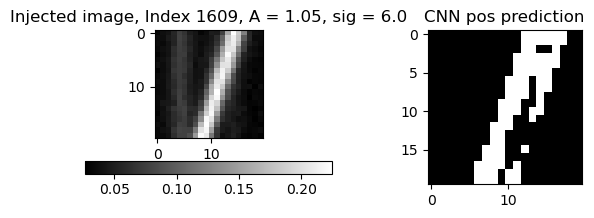

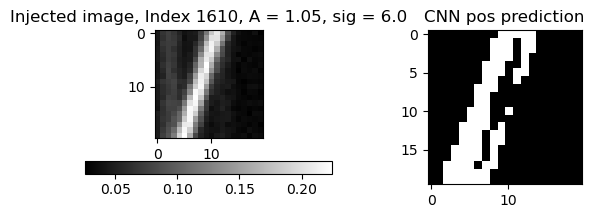

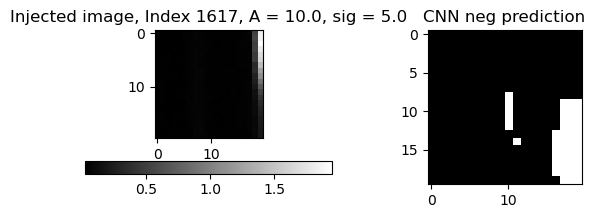

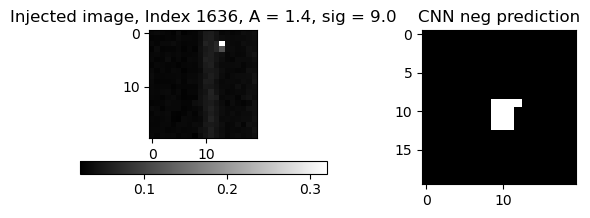

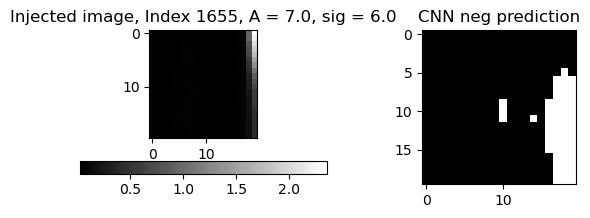

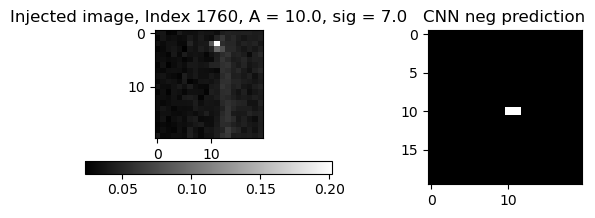

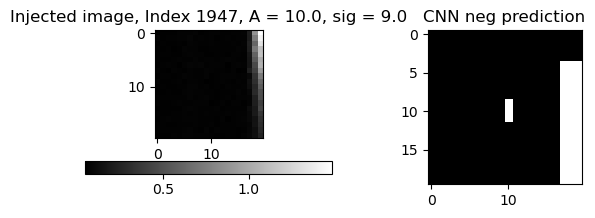

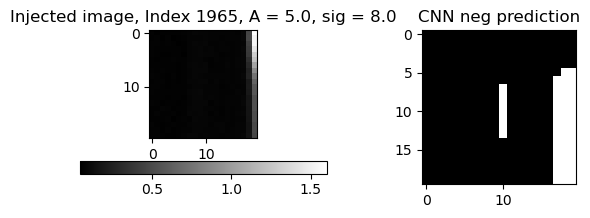

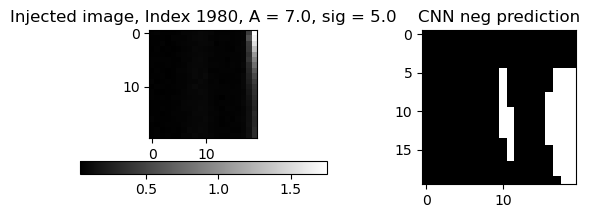

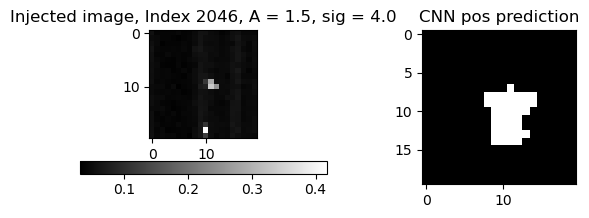

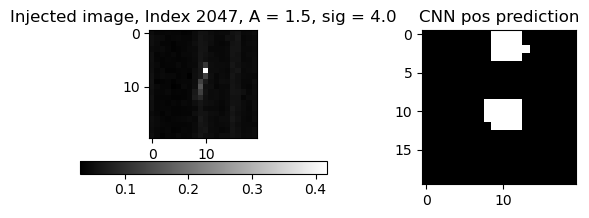

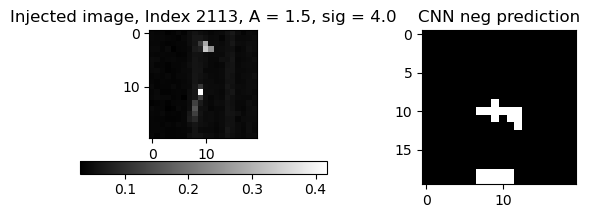

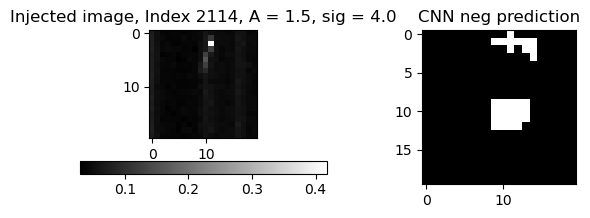

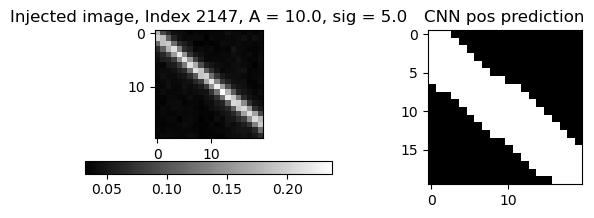

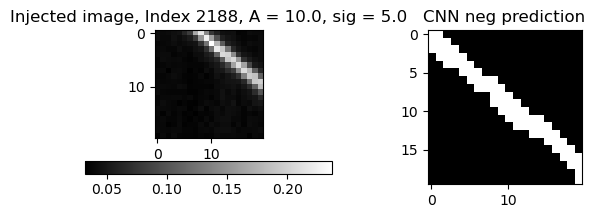

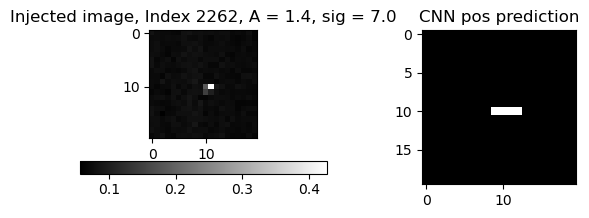

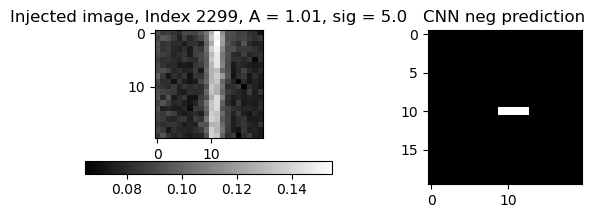

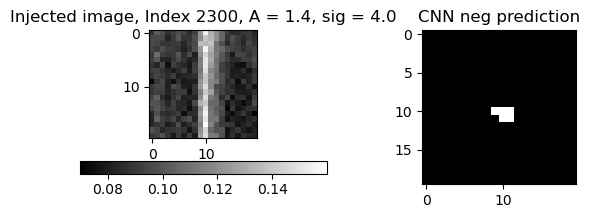

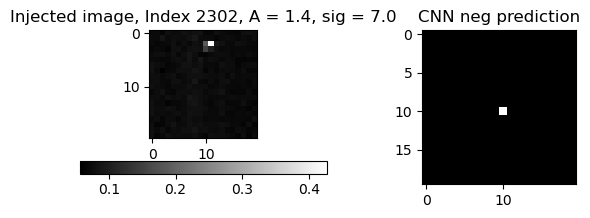

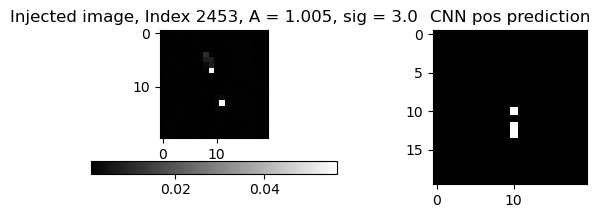

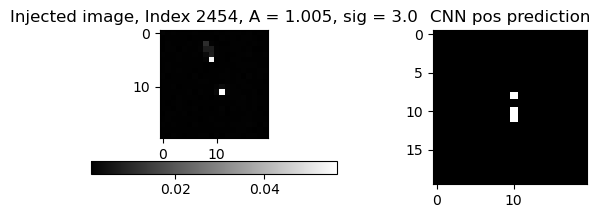

In [71]:
for index in dfs_pos["sat_finalhparam_div4"][dfs_pos["sat_finalhparam_div4"]['Diff']>10].index:
    rff.inspect_stamp_and_map(dfs_pos["sat_finalhparam_div4"], index, posneg='pos', pdirec='predsarrays_sat_finalhparam_div4')

In [78]:
!ls /lustre/lrspec/ZTF_data/efficiency_testing/new_eff_data/full_image_implantations_pos/predsarrays_sat_finalhparam_div4/

df_concat
df_matched
ztf_20221020138241_000686_zi_c02_x_0029._1_alllist
ztf_20221020138241_000686_zi_c02_x_0029._1_predsarray.npy
ztf_20221020138241_000686_zi_c02_x_0029._3_alllist
ztf_20221020138241_000686_zi_c02_x_0029._3_predsarray.npy
ztf_20221020138241_000686_zi_c02_x_0029._4_alllist
ztf_20221020138241_000686_zi_c02_x_0029._4_predsarray.npy
ztf_20221020148032_000686_zg_c03_x_0011._1_alllist
ztf_20221020148032_000686_zg_c03_x_0011._1_predsarray.npy
ztf_20221020148032_000686_zg_c03_x_0011._2_alllist
ztf_20221020148032_000686_zg_c03_x_0011._2_predsarray.npy
ztf_20221020148032_000686_zg_c03_x_0011._3_alllist
ztf_20221020148032_000686_zg_c03_x_0011._3_predsarray.npy
ztf_20221020148032_000686_zg_c07_x_0013._1_alllist
ztf_20221020148032_000686_zg_c07_x_0013._1_predsarray.npy
ztf_20221020148032_000686_zg_c07_x_0013._3_alllist
ztf_20221020148032_000686_zg_c07_x_0013._3_predsarray.npy
ztf_20221020148032_000686_zg_c07_x_0013._4_alllist
ztf_20221020148032_000686_zg_c07_x_0013._4_predsarray.np

In [125]:
pray = np.load("/lustre/lrspec/ZTF_data/efficiency_testing/new_eff_data/full_image_implantations_pos/predsarrays_offset_sat_small/ztf_20221020148032_000686_zg_c16_x_0014._4_predsarray.npy")

In [80]:
nrow, ncol = 3080, 3072 
wid=10

In [126]:
poses = pray[:, 5].reshape(ncol - 2 * wid, nrow - 2 * wid)

In [130]:
np.sum(poses>.001)

0

In [132]:
np.max(poses)

3.3022912e-05

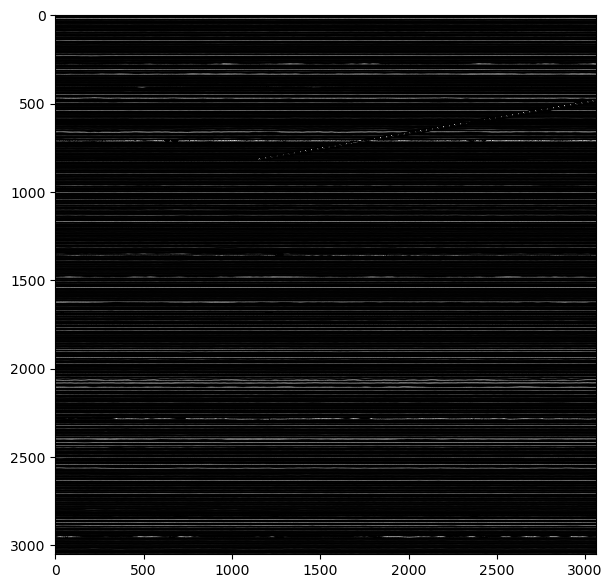

In [131]:
plt.imshow(np.sqrtposes)

In [137]:
!ls /lustre/lrspec/ZTF_data/efficiency_testing/new_eff_data

full_image_implantations_neg  full_image_implantations_pos


In [139]:
file =fits.open("/lustre/lrspec/ZTF_data/2022/1020/ztf_20221020148032_000686_zg_c16_x_0014.fits.fz")

(3000.0, 3080.0)

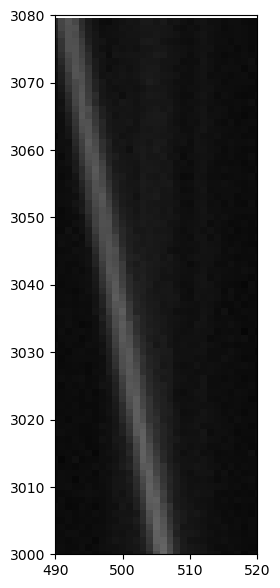

In [144]:
plt.imshow(np.sqrt(file[4].data[3000:3080,490:520]))
plt.xlim(490,520)
# plt.ylim(3000,3080)

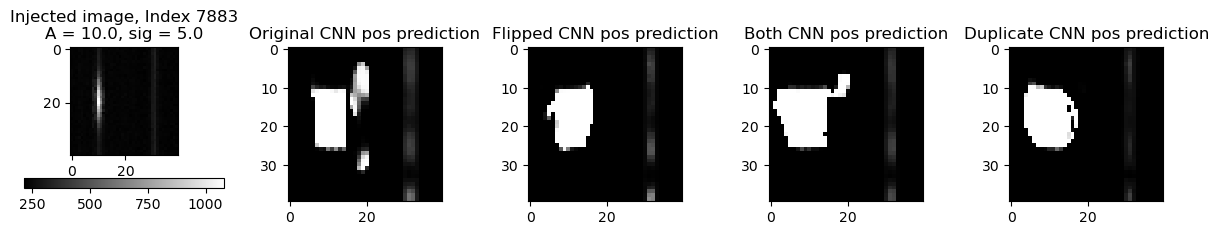

In [79]:
rff.inspect_stamp_and_all_maps(dfs_pos["original"], 7883, size=20,posneg="pos", thr=False, override="pos")

In [58]:
dfs_pos["original"].loc[23622]

Unnamed: 0.1                                              23622
Unnamed: 0                                                23622
filename               ztf_20221017148750_000831_zi_c04_x_0015.
quad                                                          1
type                                                        neg
row_from_nn                                          764.714286
col_from_nn                                               214.0
detection_size                                                7
closest_x                                                 234.0
closest_y                                                1787.0
Diff                                                       10.0
brightness_ranking                                           21
quadrant                                                      1
num_in_file_in_star                                         2.0
dup_indices                                             [23621]
is_smaller_dup                          

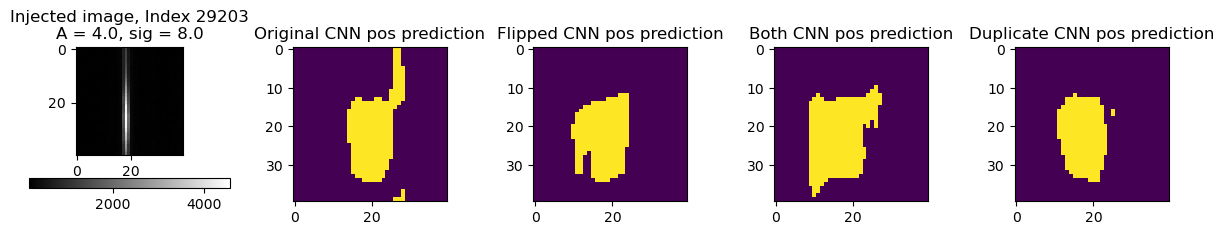

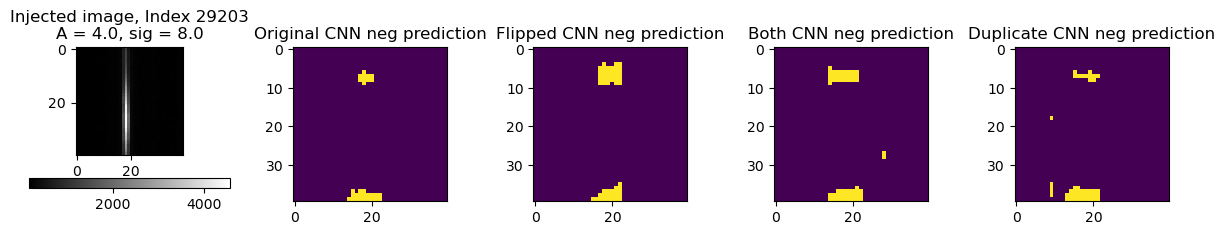

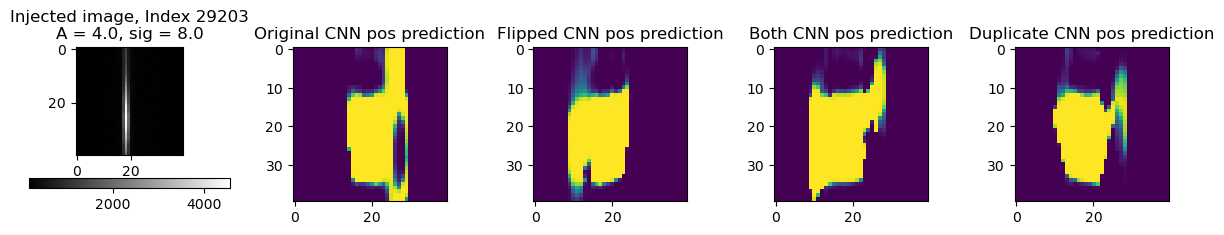

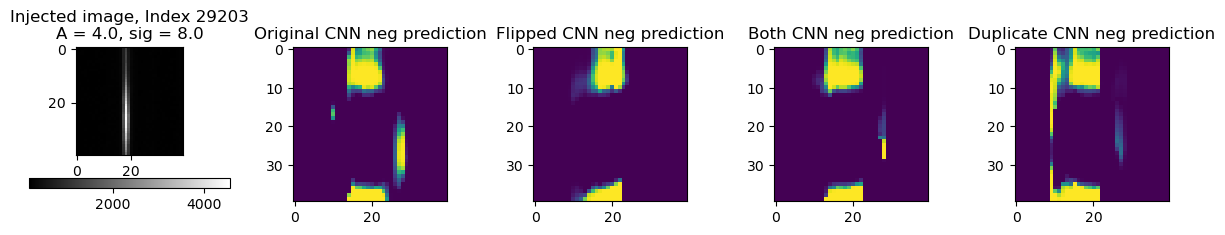

In [143]:

rff.inspect_stamp_and_all_maps(dfs_pos["original"], 29203, size=20,posneg="pos",  thr=True)
rff.inspect_stamp_and_all_maps(dfs_pos["original"], 29203, size=20,posneg="pos", override="neg", thr=True)

rff.inspect_stamp_and_all_maps(dfs_pos["original"], 29203, size=20,posneg="pos",  thr=False)
rff.inspect_stamp_and_all_maps(dfs_pos["original"], 29203, size=20,posneg="pos", override="neg", thr=False)


In [58]:
cut = dfs_neg['dup_1'][(dfs_neg['dup_1']['Diff']<(-8))*(dfs_neg['dup_1']['Diff']>(-10))]

In [85]:
len(cut)

17970

In [87]:
len(np.unique(cut['closest_y']))

62

In [86]:
cut

,Unnamed: 0.1,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,closest_y,...,brightness_ranking,quadrant,num_in_file_in_star,dup_indices,is_smaller_dup,dist_to_implant,row_from_implant,col_from_implant,A_from_implant,sig_from_implant
17,17,17,ztf_20221020138241_000686_zi_c06_x_0002.,1,pos,1708.666667,1166.666667,3,1168.0,2379.0,...,0,1,139.0,[14 15 16 18],1.0,8.975275,1714.0,1169.0,0.50,3.0
35,35,35,ztf_20221020138241_000686_zi_c06_x_0002.,1,neg,44.672727,1167.090909,110,1168.0,2379.0,...,0,1,139.0,[],0.0,737.617804,780.0,1043.0,0.75,8.0
36,36,36,ztf_20221020138241_000686_zi_c06_x_0002.,1,neg,88.000000,1166.900000,40,1168.0,2379.0,...,0,1,139.0,[],0.0,695.020295,780.0,1043.0,0.75,8.0
37,37,37,ztf_20221020138241_000686_zi_c06_x_0002.,1,neg,113.804878,1166.902439,41,1168.0,2379.0,...,0,1,139.0,[39],0.0,669.717777,780.0,1043.0,0.75,8.0
38,38,38,ztf_20221020138241_000686_zi_c06_x_0002.,1,neg,167.115385,1167.315385,130,1168.0,2379.0,...,0,1,139.0,[40 41 42],0.0,617.665348,780.0,1043.0,0.75,8.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
60847,60847,60847,ztf_20221017148750_000831_zi_c04_x_0002.,1,neg,2986.000000,457.000000,1,458.0,1367.0,...,0,1,258.0,[60846 60848],1.0,298.563226,2778.0,263.0,0.75,7.0
60848,60848,60848,ztf_20221017148750_000831_zi_c04_x_0002.,1,neg,2999.888889,456.666667,9,458.0,1367.0,...,0,1,258.0,[60847 60849],1.0,308.630147,2778.0,263.0,0.75,7.0
60849,60849,60849,ztf_20221017148750_000831_zi_c04_x_0002.,1,neg,3014.200000,456.400000,10,458.0,1367.0,...,0,1,258.0,[60848],0.0,319.352470,2778.0,263.0,0.75,7.0
60850,60850,60850,ztf_20221017148750_000831_zi_c04_x_0002.,1,neg,3040.000000,457.000000,3,458.0,1367.0,...,0,1,258.0,[60851],1.0,340.000000,2778.0,263.0,0.75,7.0


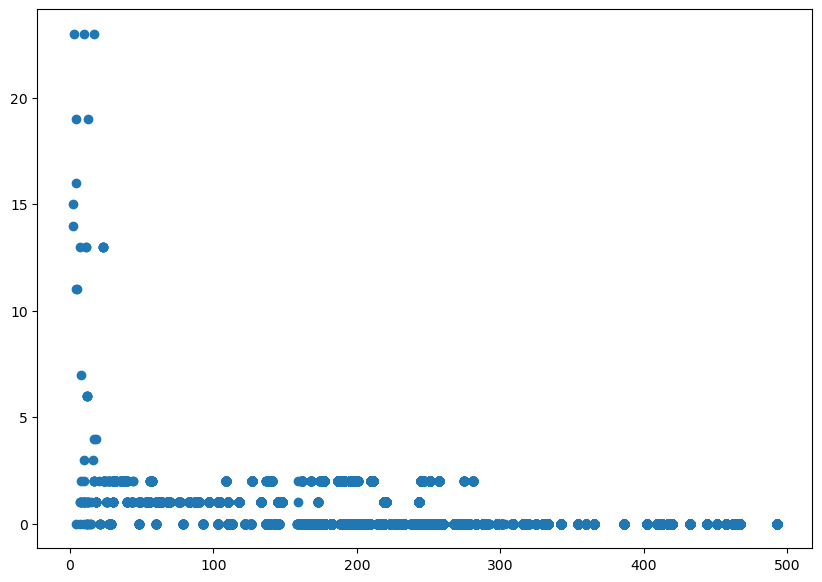

In [61]:
plt.scatter(cut['num_in_file_in_star'], cut['brightness_ranking'])

In [62]:
import corner

In [154]:
plotlist = ['detection_size', 
            # 'log_detection_size',
            'Diff',
            # 'num_in_file',
            'log_num_in_file_in_star', 
            'brightness_ranking', 'dist_to_implant'
                                ]

In [153]:
figure = corner.corner(dfs_neg['dup_1'][plotlist],
                       labels=plotlist,
    # labels=[
    #     r"$snr_local_new$",
    #     r"$detection_size$",
    #     r"$Diff$",
    #     r"$\Gamma \, [\mathrm{parsec}]$",
    # ],
    # quantiles=[0.16, 0.5, 0.84],
    show_titles=True,
    title_kwargs={"fontsize": 12},)

KeyError: "['diff', 'log_num_in_file_in_star'] not in index"

In [170]:
cleanedalittle = dfs_neg['dup_1'][np.abs(dfs_neg['dup_1']['Diff'])<20]
cleanedalittle['log_num_in_file_in_star']=np.log10(cleanedalittle['num_in_file_in_star'])
cleanedalittle['log_detection_size']=np.log10(cleanedalittle['detection_size'])
# cleanedalittle = cleanedalittle[cleanedalittle['detection_size']<400]
# cleanedalittle = cleanedalittle[cleanedalittle['is_smaller_dup']==0]
# cleanedalittle = cleanedalittle[cleanedalittle['num_in_file_in_star']<50]

/tmp/ipykernel_25126/823605091.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cleanedalittle['log_num_in_file_in_star']=np.log10(cleanedalittle['num_in_file_in_star'])
/tmp/ipykernel_25126/823605091.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cleanedalittle['log_detection_size']=np.log10(cleanedalittle['detection_size'])


In [171]:
plotlist = [ 
            'log_detection_size',
            'Diff',
            # 'num_in_file',
            'log_num_in_file_in_star', 
            'brightness_ranking', 'dist_to_implant'
                                ]

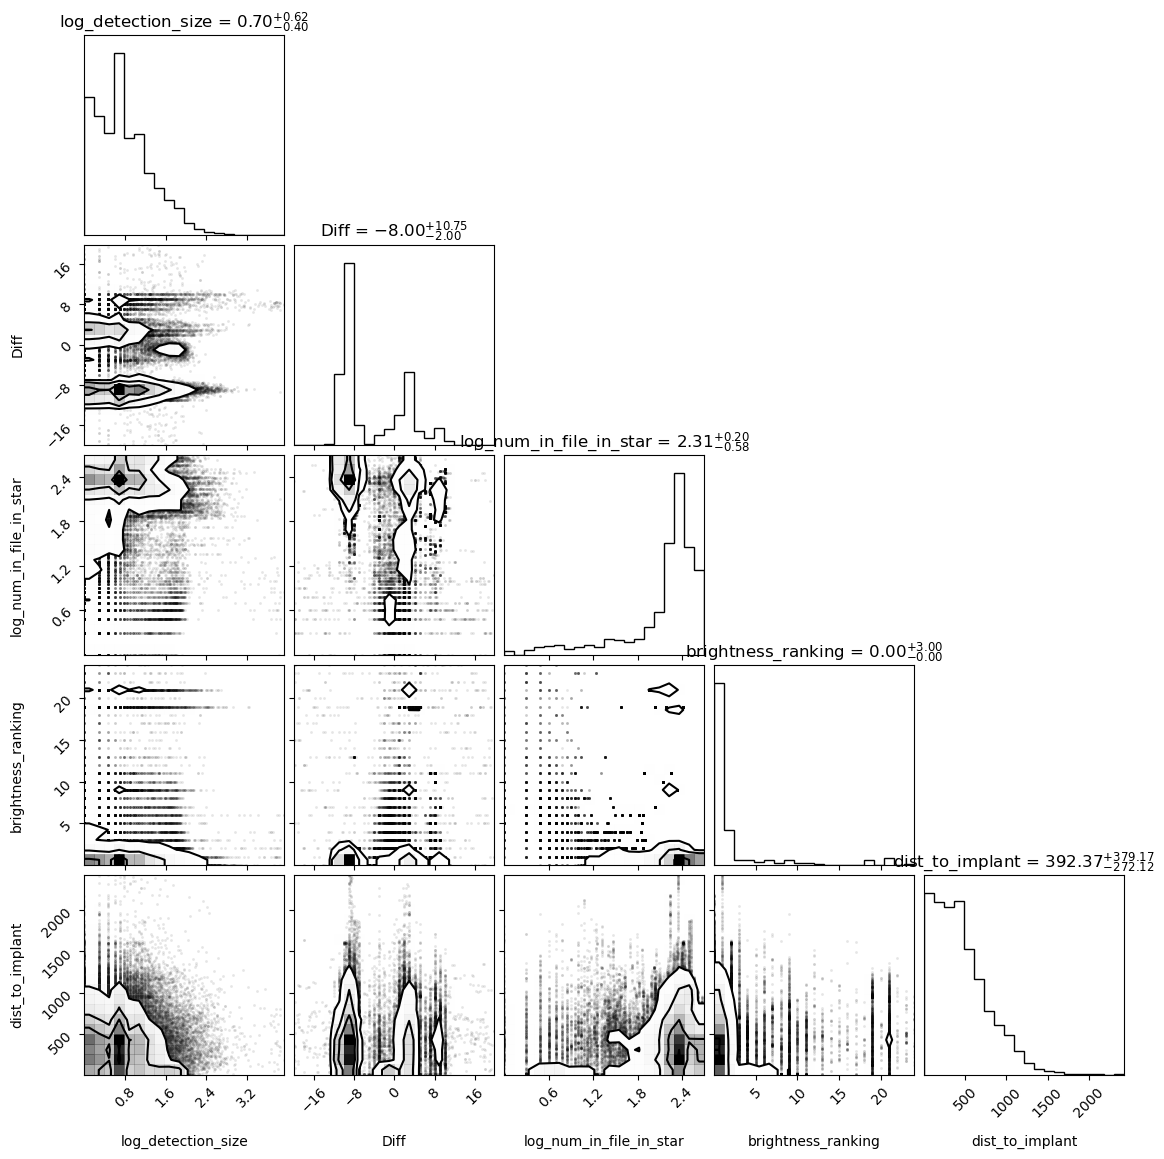

In [172]:
figure = corner.corner(cleanedalittle[plotlist],
                       labels=plotlist,
    # labels=[
    #     r"$snr_local_new$",
    #     r"$detection_size$",
    #     r"$Diff$",
    #     r"$\Gamma \, [\mathrm{parsec}]$",
    # ],
    # quantiles=[0.16, 0.5, 0.84],
    show_titles=True,
    title_kwargs={"fontsize": 12},)

In [77]:
corner.corner?

Signature:
corner.corner(
    data,
    bins=20,
    *,
    range=None,
    axes_scale='linear',
    weights=None,
    color=None,
    hist_bin_factor=1,
    smooth=None,
    smooth1d=None,
    labels=None,
    label_kwargs=None,
    titles=None,
    show_titles=False,
    title_quantiles=None,
    title_fmt='.2f',
    title_kwargs=None,
    truths=None,
    truth_color='#4682b4',
    scale_hist=False,
    quantiles=None,
    verbose=False,
    fig=None,
    max_n_ticks=5,
    top_ticks=False,
    use_math_text=False,
    reverse=False,
    labelpad=0.0,
    hist_kwargs=None,
    group='posterior',
    var_names=None,
    filter_vars=None,
    coords=None,
    divergences=False,
    divergences_kwargs=None,
    labeller=None,
    **hist2d_kwargs,
)
Docstring:
Make a *sick* corner plot showing the projections of a data set in a
multi-dimensional space. kwargs are passed to hist2d() or used for
`matplotlib` styling.

Parameters
----------
data : obj
    Any object that can be converted t

In [79]:
plotlist2 = ["Diff","num_in_file_in_star"]

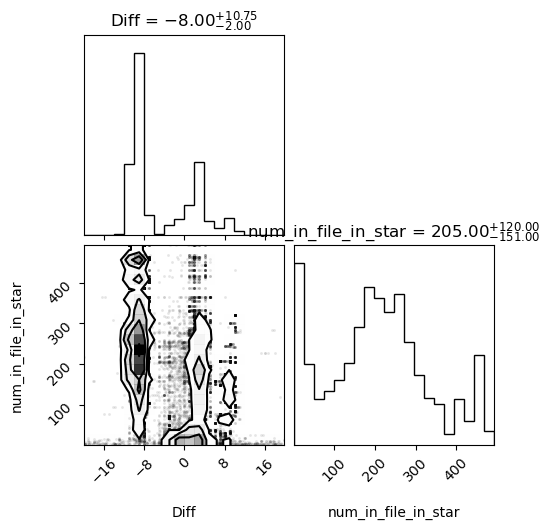

In [81]:
figure = corner.corner(dfs_neg["dup_1"][np.abs(dfs_neg["dup_1"]["Diff"])<20][plotlist2],
                       labels=plotlist2,
    # labels=[
    #     r"$snr_local_new$",
    #     r"$detection_size$",
    #     r"$Diff$",
    #     r"$\Gamma \, [\mathrm{parsec}]$",
    # ],
    # quantiles=[0.16, 0.5, 0.84],
    show_titles=True,
    title_kwargs={"fontsize": 12},)

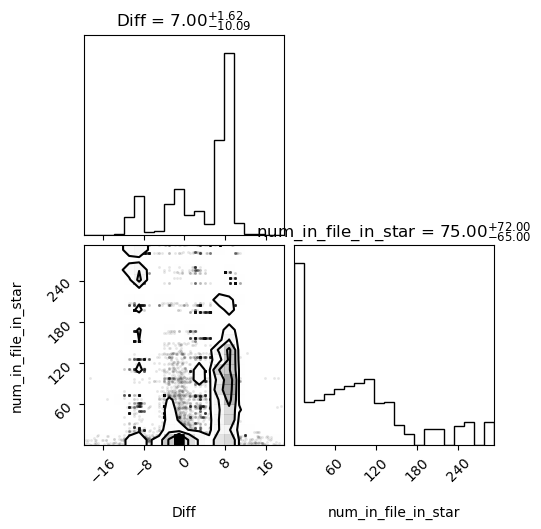

In [82]:
figure = corner.corner(dfs_pos["dup_1"][np.abs(dfs_pos["dup_1"]["Diff"])<20][plotlist2],
                       labels=plotlist2,
    # labels=[
    #     r"$snr_local_new$",
    #     r"$detection_size$",
    #     r"$Diff$",
    #     r"$\Gamma \, [\mathrm{parsec}]$",
    # ],
    # quantiles=[0.16, 0.5, 0.84],
    show_titles=True,
    title_kwargs={"fontsize": 12},)

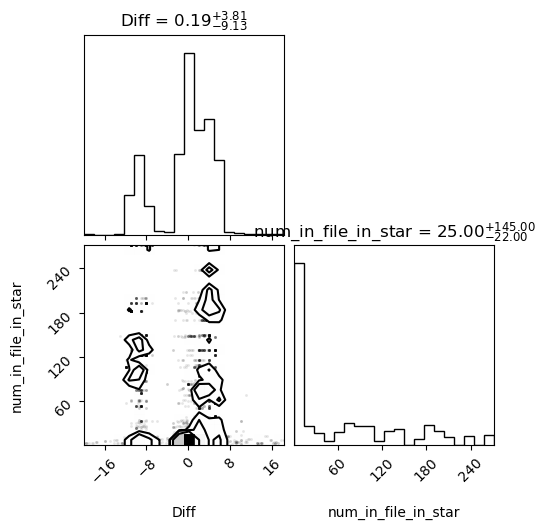

In [88]:
figure = corner.corner(dfs_pos["dup_2"][np.abs(dfs_pos["dup_2"]["Diff"])<20][plotlist2],
                       labels=plotlist2,
    # labels=[
    #     r"$snr_local_new$",
    #     r"$detection_size$",
    #     r"$Diff$",
    #     r"$\Gamma \, [\mathrm{parsec}]$",
    # ],
    # quantiles=[0.16, 0.5, 0.84],
    show_titles=True,
    title_kwargs={"fontsize": 12},)

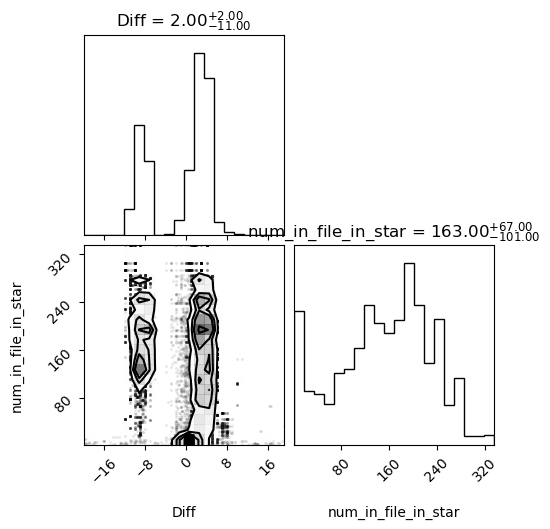

In [89]:
figure = corner.corner(dfs_neg["dup_2"][np.abs(dfs_neg["dup_2"]["Diff"])<20][plotlist2],
                       labels=plotlist2,
    # labels=[
    #     r"$snr_local_new$",
    #     r"$detection_size$",
    #     r"$Diff$",
    #     r"$\Gamma \, [\mathrm{parsec}]$",
    # ],
    # quantiles=[0.16, 0.5, 0.84],
    show_titles=True,
    title_kwargs={"fontsize": 12},)

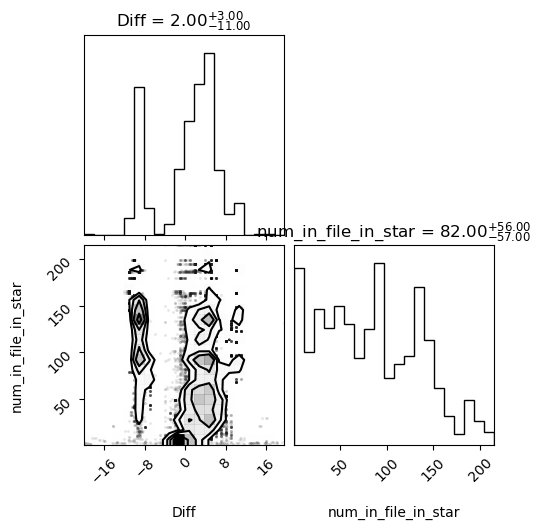

In [90]:
figure = corner.corner(dfs_neg["dup_3"][np.abs(dfs_neg["dup_3"]["Diff"])<20][plotlist2],
                       labels=plotlist2,
    # labels=[
    #     r"$snr_local_new$",
    #     r"$detection_size$",
    #     r"$Diff$",
    #     r"$\Gamma \, [\mathrm{parsec}]$",
    # ],
    # quantiles=[0.16, 0.5, 0.84],
    show_titles=True,
    title_kwargs={"fontsize": 12},)

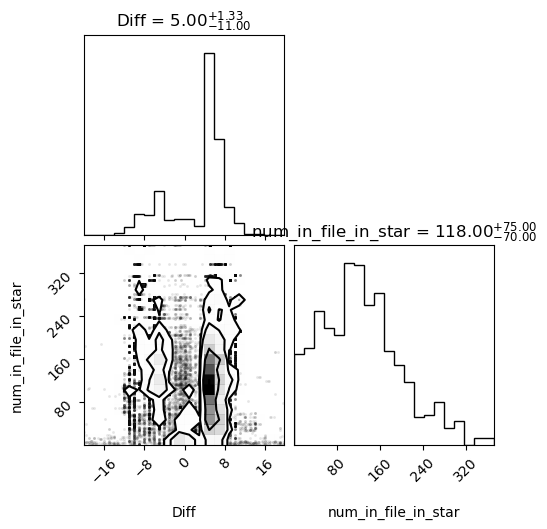

In [97]:
figure = corner.corner(dfs_neg_1["both"][np.abs(dfs_neg_1["both"]["Diff"])<20][plotlist2],
                       labels=plotlist2,
    # labels=[
    #     r"$snr_local_new$",
    #     r"$detection_size$",
    #     r"$Diff$",
    #     r"$\Gamma \, [\mathrm{parsec}]$",
    # ],
    # quantiles=[0.16, 0.5, 0.84],
    show_titles=True,
    title_kwargs={"fontsize": 12},)

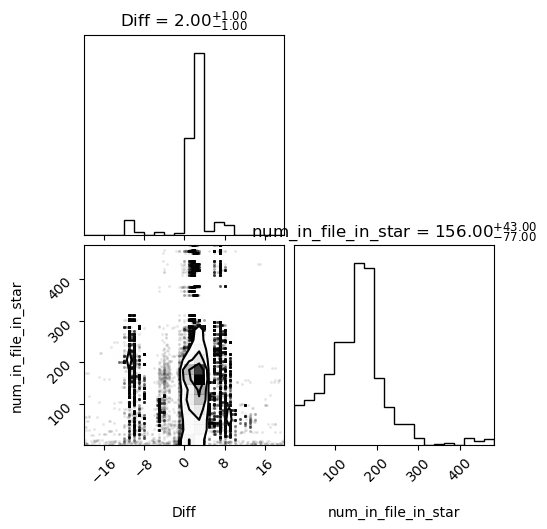

In [98]:
figure = corner.corner(dfs_neg["newrange"][np.abs(dfs_neg["newrange"]["Diff"])<20][plotlist2],
                       labels=plotlist2,
    # labels=[
    #     r"$snr_local_new$",
    #     r"$detection_size$",
    #     r"$Diff$",
    #     r"$\Gamma \, [\mathrm{parsec}]$",
    # ],
    # quantiles=[0.16, 0.5, 0.84],
    show_titles=True,
    title_kwargs={"fontsize": 12},)